# FaithfulDocVQA — a walkthrough

**Release note.** The saved outputs are viewable without executing this notebook.
Full execution and raw-response rescoring require full OCR datasets and raw model
responses not included in this release. Use the [README's public reproduction
instructions](../README.md#model-availability-and-reproduction) to recalculate
metrics from the released artifacts.

FaithfulDocVQA asks a document-VQA system to make two related decisions. Given a
page image, a question, and an **evidence table** of OCR tokens
`(id, text, bbox)`, the system reads an answer from the image, separately decides
whether that answer is supported by the supplied OCR table, and then cites
evidence-table IDs or abstains.

The code validates the three-field JSON contract, checks consistency between the
menu-answerability decision and the evidence list, and verifies that every cited
ID exists in the supplied OCR menu. These checks catch malformed outputs,
inconsistent fields, and nonexistent IDs. A real but irrelevant OCR ID can still
pass them; later sections compare citations with the dataset's fixed citation
labels and examine worked failure examples.

**Conventions in this notebook.** Every reported number is recomputed from a
committed artifact or accompanied by an explicit repository source. Cells call
the repository's implementations rather than reimplementing its scorer or data
transformations. The walkthrough recomputes reported metrics on CPU from committed
predictions and analysis artifacts; it does not rerun training or model inference.

**Qwen3-VL-4B-Instruct** is the base model used throughout. SFT trains QLoRA
adapters. Each GRPO run starts from a trained SFT adapter and continues updating
it with the reward settings for that run; the experiment map below shows the
exact lineage.

### Results at a glance

**Metric key.** Honest refusal means abstaining when none of the accepted answers
could be matched to the fixed OCR evidence table. False refusal means abstaining
when an accepted answer could be matched there. Conditional citation-label F1
compares the model’s cited OCR IDs with the dataset’s fixed citation labels on
outputs that make a structurally valid citation claim. [Section 1](#s1) explains
how the OCR evidence table and menu-answerability labels are constructed.

**Natural OCR-miss rows** are original examples whose accepted answer was not
localized in the frozen OCR menu. **Clean manufactured rows** start from
menu-answerable examples and remove the fixed cited OCR span; rows where an
accepted answer remains at another valid supporting site are excluded.

| System / checkpoint | Clean manufactured honest refusal ↑<br>`n=235` | Natural OCR-miss honest refusal ↑<br>`n=77` | False refusal on gold-menu-answerable rows ↓<br>`n=679` | Conditional citation-label F1 ↑‡<br>`eligible / 679` |
|---|---:|---:|---:|---:|
| Base Qwen3-VL — no task-specific fine-tuning | 4/235 (0.017) | 8/77 (0.104) | 14/679 (0.021) | 0.6771 (638/679 eligible) |
| SFT seed — answerable + natural OCR-miss supervision<br>ck-642 | 68/235 (0.289) | 62/77 (0.805)† | 26/679 (0.038) | 0.8412 (650/679 eligible) |
| GRPO control — abstention rewards zeroed<br>run-1 ck-150 | 62/235 (0.264) | 59/77 (0.766) | 23/679 (0.034) | 0.8296 (655/679 eligible) |
| Shaped GRPO — reward honest refusal; penalize false grounding<br>run-2 ck-150 | 204/235 (0.868) | 77/77 (1.000) | 120/679 (0.177) | 0.8694 (557/679 eligible) |
| Matched-pool SFT continuation — original GRPO pool<br>ck-150 | 195/235 (0.830) | 76/77 (0.987) | 83/679 (0.122) | 0.8592 (596/679 eligible) |
| Balanced SFT — add clean manufactured abstentions<br>run-3 ck-1296 | 212/235 (0.902) | 71/77 (0.922) | 78/679 (0.115) | 0.8758 (601/679 eligible) |
| Run-4a GRPO — balanced seed; original reward<br>ck-100 | 217/235 (0.923) | 76/77 (0.987) | 99/679 (0.146) | 0.8895 (580/679 eligible) |
| Run-4b GRPO — add false-refusal penalty<br>ck-150 | 217/235 (0.923) | 74/77 (0.961) | 91/679 (0.134) | 0.8775 (588/679 eligible) |

† **Selected-checkpoint result.** Ck-642 was chosen post hoc as the
honest-refusal maximum across six checkpoints on 46 validation abstention rows.
The table reports its observed test result because this checkpoint initialized
GRPO; §5 shows the noisy checkpoint curve and the documented 0.65–0.68 forward
estimate.

‡ **Conditional citation-label F1.** Scored only when a gold-menu-answerable row
produces a valid output claiming menu support and cites only existing menu IDs.
Coverage varies by system, and answer correctness does not determine eligibility;
read F1 together with eligible coverage and false refusal.

Run-1 and run-2 both continue the original SFT seed with GRPO; balanced SFT
instead adds clean manufactured abstention examples during supervised training;
run-4a and run-4b then continue that balanced seed with GRPO, with run-4b adding
a false-refusal penalty. See the [experiment map](#experiment-map) for the full
lineage.

- The original SFT seed learned substantial refusal on natural OCR misses but
  generalized poorly to clean manufactured evidence removals.
- Run-2 shaped GRPO substantially improved correct refusal on both abstention
  populations, while incorrect refusal increased to 120/679.
- Balanced SFT made a different trade-off, with 78/679 incorrect refusals
  rather than run-2's 120/679.
- Starting from balanced SFT, run-4b reduced incorrect refusal relative to
  run-4a from 99/679 to 91/679, while correct refusal on natural OCR misses
  fell from 76/77 to 74/77. Both systems remained at 217/235 on the clean
  manufactured set.

### Contents

| | section | what it settles |
|---|---|---|
| §1 | [The data](#s1) | where the records come from, what each field means, and one convention that matters |
| §2 | [The task, on one real record](#s2) | the prompt the model actually sees, and the fields it must return |
| §3 | [What the dataset is](#s3) | composition, and the invariants that keep it fixed |
| §4 | [Baseline: Qwen3-VL without task-specific fine-tuning](#s4) | the floor everything is measured against |
| §5 | [Supervised fine-tuning](#s5) | teaching refusal, and picking a checkpoint |
| §6 | [Manufactured abstains](#s6) | the stress test natural data cannot provide |
| §7 | [GRPO — shaping refusal behavior](#s7) | how reward settings changed the refusal trade-off |
| §8 | [Mechanism — what did the model learn?](#s8) | string matching versus checking the relevant place on the page |
| §9 | [Run 3 — balanced SFT](#s9) | the supervised follow-up motivated by run-2 |
| §10 | [Balanced SFT on the test sets](#s10) | how balanced SFT compares with the original SFT seed and the earlier GRPO runs |
| §11 | [Run 4 — pricing over-refusal](#s11) | training dynamics, checkpoint selection, and final trade-offs |
| §12 | [Limitations](#s12) | the main boundaries of the evaluation and released artifacts |

<a id="experiment-map"></a>

### Experiment map — how the training variants relate

This map shows lineage and experimental purpose. Internal labels and checkpoints
are retained for traceability.

| Plain name | Internal label / checkpoint | Starting point | Intervention | Why this run exists |
|---|---|---|---|---|
| **Base system** | `Qwen3-VL-4B-Instruct` | Instruction-tuned Qwen3-VL | No task-specific fine-tuning | Establish the baseline before project-specific fine-tuning. |
| **SFT seed** | `sft_v3_32g`, ck-642 | Base system | Supervised training on answerable examples plus natural OCR-miss abstention targets; no manufactured abstentions | Test whether ordinary supervised training teaches refusal on natural OCR misses and whether it generalizes to removed evidence. |
| **GRPO control** | `grpo_run1_seed42`, ck-150 | SFT seed ck-642 | Continue the SFT seed with GRPO, but set the honest-refusal and false-grounding reward terms to zero | Test whether continuing with GRPO changes refusal behavior when the abstention-specific rewards are disabled. |
| **Shaped GRPO** | `grpo_run2_seed42`, ck-150 | SFT seed ck-642 | Continue the same SFT seed with GRPO, rewarding honest refusal and penalizing false grounding | Test how explicit abstention rewards change refusal behavior and what false-refusal tradeoff they create. |
| **Matched-pool SFT continuation** | `sft_ck642_matched_grpo_pool_seed42`, ck-150 | SFT seed ck-642 | Continue with SFT on the original 5,000-record run-1/run-2 pool—3,000 answerable and 2,000 manufactured rows, including 377 recurrence/decoy cases—for 150 steps and 600 supervised-example exposures; fix ck-150 in advance | Compare further supervised training with run-2 using the same starting checkpoint, 5,000-record training pool, and 600 prompt exposures. |
| **Balanced SFT** | `sft_v3_balanced_nodecoy`, ck-1296 | Base system | Train from the base model with 1,764 clean manufactured abstention targets added to the supervised mix | Test whether manufactured abstention examples can produce strong refusal behavior through supervised training alone. |
| **Run-4a** | `grpo_run4a_seed42`, ck-100 | Balanced-SFT ck-1296 | Continue balanced SFT with GRPO using the same abstention reward settings as shaped GRPO: reward honest refusal, penalize false grounding, and leave false refusal unpenalized | Test what GRPO adds when it starts from the stronger balanced-SFT checkpoint. |
| **Run-4b** | `grpo_run4b_seed42`, ck-150 | Balanced-SFT ck-1296 | Use the same balanced-SFT starting point and GRPO setup as run-4a, but add a −0.2 penalty for false refusal | Test whether penalizing false refusal reduces over-refusal and what refusal ability is lost in exchange. |

In [7]:
import json
import os
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import display
from tqdm import TqdmWarning

# Standard-library and notebook setup
warnings.filterwarnings("ignore", category=TqdmWarning)  # cosmetic tqdm/ipywidgets warning

cwd = Path.cwd().resolve()
sentinels = (Path("scripts/eval_scorer.py"), Path("data/master.jsonl"))
ROOT = next(
    (candidate for candidate in (cwd, *cwd.parents)
     if all((candidate / sentinel).is_file() for sentinel in sentinels)),
    None,
)
if ROOT is None:
    raise RuntimeError(
        f"Repository root not found above {cwd}; expected "
        "scripts/eval_scorer.py and data/master.jsonl."
    )

root_string = str(ROOT)
if root_string not in sys.path:
    sys.path.insert(0, root_string)
os.chdir(ROOT)

# Canonical repository data and prompt-rendering helpers
from scripts.format_sft import build_messages, load_split

# Canonical scoring helpers
from scripts.eval_scorer import classify, score

# Canonical manufactured-abstention helpers
from scripts.build_manufactured_abstains import (
    answer_recurs,
    drop_and_renumber,
    first_doctype,
)

print("repo:", ROOT.name, "| imports OK (repo scripts only)")

# Reusable public plotting helpers
from scripts.plot_training_dynamics import (
    plot_final_operating_points,
    plot_run4_outcome_dynamics,
    plot_run4_reward_dynamics,
    plot_run4_validation_dynamics,
    plot_sft_checkpoint_behavior,
)


repo: FaithfulDocVQA-GRPO | imports OK (repo scripts only)


<a id="s1"></a>

## 1 · The data

Each DocVQA source record provides a page image, a text question, and one or
more accepted text answers. It does not provide answer-level bounding boxes or
gold OCR-token citation labels.

The data were accessed through
[`lmms-lab/DocVQA`](https://huggingface.co/datasets/lmms-lab/DocVQA), with source
documents associated with the
[UCSF Industry Documents Library](https://www.industrydocuments.ucsf.edu/).
Page images are not distributed in this repository; this walkthrough uses frozen
derived records and committed evaluation artifacts.

**How this project constructs supervision.** Each page image passes through the
frozen Tesseract implementation in
[`phase0.pipeline.extract_ocr_tokens`](../phase0/pipeline.py), producing the
**evidence table**: numbered OCR tokens with text and bounding boxes. The frozen
fuzzy sliding-window localizer in
[`phase0.phase05`](../phase0/phase05.py) searches the accepted answer variants using
the documented 0.85/0.7/0.6/0.5 threshold cascade and numeric fallback.

A successful localization labels the frozen OCR menu as **menu-answerable**. The
matched token IDs become frozen citation labels; they are not independently
adjudicated semantic ground truth. A localization miss becomes a natural OCR-miss
abstention target. The accepted answer may still be visible in the page image even
when it cannot be grounded in the frozen OCR menu.

For a natural OCR-miss row, the training target keeps the accepted answer in
`found_answer`, sets `answerable_from_menu=false`, and leaves `evidence_ids` empty.

Records were assigned by `doc_id`, so the same identifier cannot cross splits. A
later image-level audit found one exact train/test duplicate and one near-duplicate
across train/validation. The clean manufactured `n=235` headline is unaffected;
duplicate-excluded natural-test sensitivity is presented later.

Metric cells recompute results from fixed evaluation records and committed
prediction artifacts; they do not rerun OCR, training, or model inference.
Image-display cells use an optional local image cache and skip when images are
absent. Dataset regeneration is separate from routine metric reproduction.

The next cell is an executable field guide: its descriptions are written by hand,
then checked against one real `master.jsonl` record so undocumented or missing
fields remain visible.

In [8]:
# Executable field guide: document every master.jsonl field, then compare the
# guide with one real record so schema drift remains visible.
sample_record = json.loads(open("data/master.jsonl").readline())
FIELD_GUIDE = {
 "identity":   [("record_id", "DocVQA questionId, stringified — the join key everywhere"),
                ("doc_id",    "source document/page identifier; multiple question records may share one ID, and distinct IDs are not guaranteed to be image-unique"),
                ("split",     "train | validation | test — assigned by doc_id; doc_id values do not cross splits, but image-level duplicates can"),
                ("image_path","repo-relative path into the optional local page-image cache; page images are not committed")],
 "task":       [("question",    "the DocVQA question, verbatim"),
                ("gold_answers","all accepted answer variants; [0] is canonical"),
                ("doc_type",    "DocVQA question_types — a list, and may be multi-label")],
 "evidence":   [("ocr_menu",     "the frozen evidence table: [{id, text, bbox}], ids 0..N-1"),
                ("ocr_menu_hash","sha256 over the canonicalized table"),
                ("cited_ids",    "frozen citation labels: OCR-menu token ids selected by the localizer")],
 "supervision":[("gold_localized", "frozen menu-answerability label: did the localizer find an accepted answer in the menu?"),
                ("target_answer",  "legacy v1 target field: gold_answers[0] if localized, otherwise the literal 'unanswerable'; live v3 SFT derives found_answer separately"),
                ("target_is_abstain","== (not gold_localized), by construction"),
                ("abstain_reason", "'ocr_miss' on natural abstention rows — build provenance, not a model output")],
 "diagnostic": [("localizer_score", "the fuzzy match score behind cited_ids — read by no downstream code")],
}
documented_fields = set()
print("MASTER.JSONL FIELD GUIDE")
for group_name, fields in FIELD_GUIDE.items():
    print(f"{group_name.upper()}")
    for field_name, description in fields:
        documented_fields.add(field_name)
        print(f"   {field_name:<20} {description}")
record_fields = set(sample_record)
undocumented_fields = sorted(record_fields - documented_fields)
missing_fields = sorted(documented_fields - record_fields)
print("\nfields present on the record but not grouped above:", undocumented_fields or "none")
print("grouped fields absent from the record:", missing_fields or "none")

MASTER.JSONL FIELD GUIDE
IDENTITY
   record_id            DocVQA questionId, stringified — the join key everywhere
   doc_id               source document/page identifier; multiple question records may share one ID, and distinct IDs are not guaranteed to be image-unique
   split                train | validation | test — assigned by doc_id; doc_id values do not cross splits, but image-level duplicates can
   image_path           repo-relative path into the optional local page-image cache; page images are not committed
TASK
   question             the DocVQA question, verbatim
   gold_answers         all accepted answer variants; [0] is canonical
   doc_type             DocVQA question_types — a list, and may be multi-label
EVIDENCE
   ocr_menu             the frozen evidence table: [{id, text, bbox}], ids 0..N-1
   ocr_menu_hash        sha256 over the canonicalized table
   cited_ids            frozen citation labels: OCR-menu token ids selected by the localizer
SUPERVISION
   gold_loc

**One convention worth stating plainly.** The fixed citation label is whatever the
fuzzy localizer matched **first** — a best-effort scan, not an adjudication. When an
answer string appears at more than one place on the page, the convention selects
the scan-order-first occurrence; citing another occurrence can therefore miss the
fixed label even when the same string appears there.

That is measurable, and it has been measured
([`docs/analysis/multi_occurrence_audit.md`](../docs/analysis/multi_occurrence_audit.md)):
Across all splits, **533/4,496 answerable rows (11.9%)** have two or more
*citable* places spelling an accepted answer. On the answerable test split,
**80/679 rows (11.8%)** meet that condition. A permissive
counterfactual that credits alternate same-string sites changes citation F1 by
**+0.0148** for the SFT seed, **+0.0117** for run-1, **+0.0183** for run-2, and
**+0.0133** for balanced SFT. It does not reorder those four systems. This is a
citation-label sensitivity analysis, not a bound on semantic citation validity.

The project keeps the fixed labels and reports this sensitivity rather than silently
relabeling the test set. Per-site adjudication remains future work and is listed as
a possible extension in the local run-3 analysis plan.

<a id="s2"></a>

## 2 · The task, on one real record

Below is an actual training-distribution record, rendered through the **exact prompt
pipeline the model sees** (`scripts/format_sft.build_messages`): the system instructions,
the question, and the evidence table. The model's job is the JSON at the end — **the three
fields it must return** (the repo calls this the *3-field contract*):

- `found_answer` — what it reads off the **page image** (perception),
- `answerable_from_menu` — whether that answer is **citable from the evidence table** (attribution),
- `evidence_ids` — the table id(s) that support it (empty when abstaining).

This record was selected because its complete evidence table is small: all five
OCR tokens are shown below, not a truncated preview.

Source page: [view the original DocVQA validation record on Hugging Face
(question 24580)](https://huggingface.co/datasets/lmms-lab-encoder/DocVQA/viewer/DocVQA/validation?row=1).

The displayed cell uses `include_target=True` so the notebook can show both the prompt
and its supervised completion. At inference, `include_target=False` omits the assistant
target. During SFT tokenization, prompt-only and prompt-plus-target renders establish
the label boundary; prompt labels are set to −100, so cross-entropy is computed only
on completion tokens (`scripts/train_sft.py::tokenize_example`, guarded by
`tests/test_loss_mask.py`).

GRPO does not use this SFT label mask: it samples completions, scores them with the
reward function, and updates the policy from completion-token probabilities rather
than cross-entropy against a gold completion. For background on policy-gradient
training and GRPO, see [Nathan Lambert, *RLHF and Post-Training Book: Policy Gradient
Algorithms*](https://rlhfbook.com/c/06-policy-gradients).

In [9]:
# one committed answerable record with a small evidence table (deterministic pick)
val = load_split("validation", "B")   # mode-B = all records, no localizer filter

# smallest menu wins; record_id breaks ties so the pick never changes between runs
rec = min((r for r in val if not r["target_is_abstain"] and len(r["ocr_menu"]) <= 25),
          key=lambda r: (len(r["ocr_menu"]), r["record_id"]))

msgs = build_messages(rec, include_target=True)   # include_target=True adds the supervised answer
print(f"record {rec['record_id']} | doc {rec['doc_id']} | {first_doctype(rec['doc_type'])} "
      f"| evidence table: {len(rec['ocr_menu'])} tokens")
sys_prompt = msgs[0]["content"]
print(f"\n-- SYSTEM ({len(sys_prompt)} chars, shown in full) --\n{sys_prompt}")
print("\n-- USER --\n" + msgs[1]["content"][1]["text"])
print("\n-- TARGET (the supervised completion) --\n" + msgs[2]["content"])

record 24580 | doc 7027 | others | evidence table: 5 tokens

-- SYSTEM (833 chars, shown in full) --
You are a document visual-question-answering system. You are given a page image, a question, and a numbered OCR token menu. Each menu line is `<id>\t<text>\t<x1,y1,x2,y2>` — the integer id, the token text, and its bounding box.
First read the answer from the page IMAGE; then decide whether that answer can be cited from the OCR menu.
Output ONLY a single JSON object with exactly three fields:
  "found_answer": the answer read from the page image (a string); use "unanswerable" only if the answer cannot be determined from the image.
  "answerable_from_menu": true if the answer is supported by OCR token id(s) in the menu, otherwise false (a boolean).
  "evidence_ids": the menu token id(s) supporting the answer (a list of integers) — non-empty when answerable_from_menu is true, and [] when false.
No other text, no explanation.

-- USER --
Question: What is name of university?

OCR tokens:
0	

In [10]:
# the page this record is asking about
from IPython.display import Image as _Img, display as _disp
_p = Path("data/images") / Path(rec["image_path"]).name
if _p.exists():
    print(f"{rec['question']}   (accepted answer: {rec['gold_answers'][0]!r})")
    _disp(
        _Img(filename=str(_p), width=520),
        metadata={"image/png": {"alt": "DocVQA source page for the worked task example."}},
    )
else:
    print("page image not present in the optional local image cache; "
          "the prompt and metric cells remain reproducible without it")

In [11]:
# Retrieve this record's saved ck-642 prediction; this does not load the
# checkpoint or rerun inference.
gens = json.load(open("data/checkpoints/eval/sft_B_seed42/gen_checkpoint-642.json"))
# next() = first match; raises if absent — a missing record must fail loudly, never score as 0
raw = next(r["raw"] for r in gens["records"] if r["record_id"] == rec["record_id"])
facts = classify(rec, raw)   # the repo's single scorer — same code trains GRPO and reports evals
print("model output :", raw)
print("scored bucket:", facts["bucket"], "| found_answer correct:", facts["found_answer_correct"],
      "| per-record citation F1:", facts["evidence_reward"])
# note: msgs[1]["content"] is a LIST of blocks (image, text) — the standard multimodal chat format

model output : {"found_answer":"University of California","answerable_from_menu":true,"evidence_ids":[0,1,2]}
scored bucket: valid_citation | found_answer correct: True | per-record citation F1: 1.0


### The outcome taxonomy (used everywhere below)

Every model output lands in exactly one bucket. The scorer applies this priority
order so the categories remain exclusive (`scripts/eval_scorer.py::classify`):

| bucket | one-line definition |
|---|---|
| `contradiction` | The output passes schema validation, but its fields disagree—for example, `answerable_from_menu=false` with evidence IDs, or `true` with none. |
| `malformed` | No valid contract object is produced: the output is not a string, has no balanced JSON object, contains invalid or non-object JSON, or fails schema validation because fields are missing, extra, or the wrong type. Contradictions are reported separately. |
| `fabrication` | After the contradiction and malformed checks, at least one cited ID is absent from the supplied OCR menu. This is detectable from the input alone, without reference labels. |
| `valid_citation` | On a menu-answerable row, the model claims menu support and cites only IDs that exist in the OCR table. This establishes a structurally valid citation claim. Citation-label F1 separately measures how well those IDs match the fixed citation labels; answer correctness is also scored separately. |
| `honest_abstain` | The model abstains on a row labeled menu-unanswerable. |
| `false_abstain` | The model abstains on a row labeled menu-answerable. |
| `false_grounding` | The model claims menu support on a row labeled menu-unanswerable. Because the cited IDs can exist, this is the hardest failure to detect at inference without a reference label or semantic check. |
| `uncited_answer` | Defensive final branch. It is unreachable for a successfully validated three-field output because `answerable_from_menu` must be Boolean and flag/evidence mismatches are contradictions. |

Two metrics recur. **Honest-refusal rate** is the share of rows labeled
menu-unanswerable that the model abstains on. **Conditional citation-label F1** pools
citation-ID overlap only over scorer-eligible `valid_citation` rows. Eligibility varies
by system, and answer correctness does not determine inclusion. The metric therefore
is not an end-to-end semantic-grounding score; the internal aggregate key remains
`citation_f1_gated` (`scripts/eval_scorer.py::aggregate`).

<a id="s3"></a>

## 3 · What the dataset is

Built once and kept fixed, including the original Tesseract OCR errors. When the
frozen localizer does not find an accepted answer in the OCR menu, the record becomes
a natural OCR-miss abstention target rather than being retrospectively repaired
(`# source: docs/faithfuldocvqa_scope.md §6, docs/PROVENANCE.md §2`).

In [12]:
from collections import Counter
import statistics as st
master = [json.loads(l) for l in open("data/master.jsonl")]
splits = Counter(r["split"] for r in master)
abst = [r for r in master if r["target_is_abstain"]]
print(f"records: {len(master)}  | splits: {dict(splits)}")
print(f"doc types: {dict(Counter(first_doctype(r['doc_type']) for r in master).most_common())}")
print(f"natural abstains: {len(abst)} ({len(abst)/len(master):.1%}) — reasons: "
      f"{dict(Counter(r['abstain_reason'] for r in abst))}")
m_abst = st.median(len(r["ocr_menu"]) for r in abst)
m_ans  = st.median(len(r["ocr_menu"]) for r in master if not r["target_is_abstain"])
print(f"median evidence-table size: abstain rows {m_abst:.0f} tokens vs answerable {m_ans:.0f} "
      f"— the abstain class is OCR-sparse by construction")

records: 4932  | splits: {'train': 3423, 'validation': 753, 'test': 756}
doc types: {'table/list': 1640, 'layout': 1431, 'form': 805, 'free_text': 742, 'figure/diagram': 265, 'others': 30, 'Yes/No': 19}
natural abstains: 436 (8.8%) — reasons: {'ocr_miss': 436}
median evidence-table size: abstain rows 42 tokens vs answerable 164 — the abstain class is OCR-sparse by construction


**Why so few abstains?** Natural OCR-misses are ~9% of the data — scarcity that shapes
everything later: supervised training sees few refusal examples, which is what motivates the
manufactured abstains of [§6](#s6). Frozen-ness is enforced by live invariants:

In [13]:
# Check basic consistency of the committed records; this cell does not rerun OCR.
# Split overlap is checked by doc_id, so it cannot detect the same page stored under different IDs.
by_split = {}
for r in master: by_split.setdefault(r["split"], set()).add(r["doc_id"])
assert not (by_split["train"] & by_split["validation"]), "doc-ID overlap train/validation"
assert not (by_split["train"] & by_split["test"]), "doc-ID overlap train/test"
assert not (by_split["validation"] & by_split["test"]), "doc-ID overlap validation/test"
print("PASS doc-ID partitioning — no doc_id appears in more than one split "
      f"({len(by_split['train'])}/{len(by_split['validation'])}/{len(by_split['test'])} docs)")
assert all(r["abstain_reason"] == "ocr_miss" for r in abst)
print("PASS abstain provenance — all", len(abst), "abstains are natural ocr_miss")
assert all([t["id"] for t in r["ocr_menu"]] == list(range(len(r["ocr_menu"]))) for r in master)
print("PASS evidence-table ids — contiguous 0..N-1 in every record")
bad = [r["record_id"] for r in master if not r["target_is_abstain"]
       and not set(r["cited_ids"]) <= {t["id"] for t in r["ocr_menu"]}]
assert not bad, bad[:5]
print("PASS frozen citation-label membership — every menu-answerable record's "
      "cited_ids ⊆ its table")

PASS doc-ID partitioning — no doc_id appears in more than one split (866/184/184 docs)
PASS abstain provenance — all 436 abstains are natural ocr_miss
PASS evidence-table ids — contiguous 0..N-1 in every record
PASS frozen citation-label membership — every menu-answerable record's cited_ids ⊆ its table


<a id="s4"></a>

## 4 · Baseline: Qwen3-VL without task-specific fine-tuning

The baseline is the instruction-tuned
[**Qwen3-VL-4B-Instruct**](https://huggingface.co/Qwen/Qwen3-VL-4B-Instruct)
without project-specific fine-tuning. Predictions were generated without random
sampling (`do_sample=false`) and were limited to 128 new tokens. The saved
predictions are committed under `data/checkpoints/eval/`; this notebook scores
those outputs with the repository’s scoring code.

**Some schema failures are unsurprising.** Qwen3-VL-4B-Instruct is already
instruction-tuned, and the prompt explicitly requests JSON, but the baseline has not
been fine-tuned on this project's exact three-field contract. About **3%** of outputs
fail parsing or contract validation; that rate is reported rather than repaired
(`# source: docs/analysis/base_model_eval.md` — overall malformed 0.0319 validation /
0.0344 test).

In [14]:
def score_gen(gen_path, records):
    d = json.load(open(gen_path))
    raw = {r["record_id"]: r.get("raw") for r in d["records"]}
    return score(records, raw)["overall"]   # scripts.eval_scorer.score — the committed scorer

def row(agg):
    ab, an, f1 = agg["bucket_rates"]["abstain"], agg["bucket_rates"]["answerable"], agg["citation_f1_gated"]
    return (f"honest_abstain {ab['honest_abstain']:.3f} | false_abstain {an['false_abstain']:.3f} | "
            f"valid_citation (structural) {an['valid_citation']:.3f} | "
            f"conditional citation-label F1 {f1['micro_f1']:.3f} "
            f"({f1['n_valid_citation']}/{agg['n_answerable']} eligible) | "
            f"malformed {agg['malformed_rate']:.3f}")

for split in ("validation", "test"):
    recs = load_split(split, "B")
    agg = score_gen(f"data/checkpoints/eval/sft_B_seed42/gen_base_{split}.json", recs)
    print(f"BASE, {split:10s} (n={agg['n']}: {agg['n_abstain']} abstain / {agg['n_answerable']} answerable)")
    print("  " + row(agg))

BASE, validation (n=753: 46 abstain / 707 answerable)
  honest_abstain 0.174 | false_abstain 0.011 | valid_citation (structural) 0.953 | conditional citation-label F1 0.688 (674/707 eligible) | malformed 0.032
BASE, test       (n=756: 77 abstain / 679 answerable)
  honest_abstain 0.104 | false_abstain 0.021 | valid_citation (structural) 0.940 | conditional citation-label F1 0.677 (638/679 eligible) | malformed 0.034


Before project-specific fine-tuning, Qwen3-VL **rarely abstains** (0.10–0.17 on
natural OCR-miss rows) and reaches citation-label F1 around 0.68. Everything that
follows is measured against this baseline.

<a id="s5"></a>

## 5 · Supervised fine-tuning

**The v1 experiment, in two sentences.** Under the original two-field contract, an
answer-only control produced 0/46 honest refusals on validation rows labeled
menu-unanswerable at every checkpoint. The answer-plus-abstention treatment reached
34/46 = 0.739 while its citation metric remained similar. In that setup, explicit
abstention examples were necessary to produce the desired refusal behavior; this
does not establish that refusal was absent from the model’s prior training in
general. See [`docs/DECISIONS.md`](../docs/DECISIONS.md) §1 and
[`docs/PROVENANCE.md`](../docs/PROVENANCE.md) §1. These are historical v1 results
and are not blended with the three-field v3 results below.

**The v3 run** supplies the checkpoints used downstream. Its GPU training commands
are recorded here but are not executed by the walkthrough:

```bash
# train 3 epochs -> generate raw validation outputs per checkpoint
bash scripts/unattended_run.sh data/checkpoints/sft_v3_32g B 42 3 8
# invokes: python scripts/train_sft.py --mode B --seed 42 \
#     --output-dir data/checkpoints/sft_v3_32g --epochs 3 --save-total-limit 8 --no-wandb
```

Recipe: QLoRA 4-bit NF4, LoRA r16/α32 on language q/k/v/o with the vision tower
frozen, learning rate 1e-4 with cosine scheduling, batch 1 × accumulation 8, and
completion-only loss. Prompt tokens are masked to −100; the required
[`test_loss_mask.py`](../tests/test_loss_mask.py) protects this boundary. See the
committed [`TrainConfig`](../scripts/train_sft.py) and
[`sft_v3_32g` configuration](../docs/run_configs/sft_v3_32g_training_config.json).

In [15]:
# The v3 validation checkpoint curve, plus one separately labeled selected-checkpoint
# test result. Test generations from other checkpoints are not selection evidence.
from collections import Counter

val_recs, test_recs = load_split("validation", "B"), load_split("test", "B")

def score_gen_with_counts(
    gen_path: str,
    records: list[dict],
) -> tuple[dict, Counter[str]]:
    generation = json.load(open(gen_path))
    raw_by_id = {
        row["record_id"]: row.get("raw") for row in generation["records"]
    }
    missing = [
        record["record_id"]
        for record in records
        if record["record_id"] not in raw_by_id
    ]
    assert not missing, f"join coverage: {len(missing)} missing from {gen_path}"

    outcomes = [
        classify(record, raw_by_id[record["record_id"]])
        for record in records
    ]
    bucket_counts = Counter(outcome["bucket"] for outcome in outcomes)
    aggregate = score(records, raw_by_id)["overall"]
    assert sum(bucket_counts.values()) == len(records)
    assert (
        bucket_counts["valid_citation"]
        == aggregate["citation_f1_gated"]["n_valid_citation"]
    )
    return aggregate, bucket_counts

print(
    f"{'ckpt':>6} | {'honest refusal /46':>18} | {'false refusal /707':>18} | "
    f"{'conditional citation-label F1':>29} | {'eligible /707':>13}"
)
print("-" * 99)
for ck in (214, 428, 642, 856, 1070, 1284):
    aggregate, counts = score_gen_with_counts(
        f"data/checkpoints/eval/sft_B_seed42/gen_checkpoint-{ck}.json",
        val_recs,
    )
    citation = aggregate["citation_f1_gated"]
    mark = "  <- selected to initialize GRPO" if ck == 642 else ""
    print(
        f"{ck:>6} | {counts['honest_abstain']:>2}/46"
        f"{'':>13} | {counts['false_abstain']:>2}/707"
        f"{'':>12} | {citation['micro_f1']:>29.3f} | "
        f"{counts['valid_citation']:>3}/707{mark}"
    )

selected_test, selected_test_counts = score_gen_with_counts(
    "data/checkpoints/eval/sft_B_seed42/gen_test_checkpoint-642.json",
    test_recs,
)
selected_test_f1 = selected_test["citation_f1_gated"]
print("\nSELECTED-CHECKPOINT TEST RESULT — observed result, not selection evidence")
print(
    "ck-642 | natural OCR-miss honest refusal "
    f"{selected_test_counts['honest_abstain']}/77 | "
    f"false refusal {selected_test_counts['false_abstain']}/679 | "
    f"conditional citation-label F1 {selected_test_f1['micro_f1']:.3f} "
    f"({selected_test_counts['valid_citation']}/679 eligible)"
)

  ckpt | honest refusal /46 | false refusal /707 | conditional citation-label F1 | eligible /707
---------------------------------------------------------------------------------------------------
   214 | 17/46              |  4/707             |                         0.843 | 702/707
   428 | 11/46              |  1/707             |                         0.867 | 706/707
   642 | 39/46              | 12/707             |                         0.873 | 695/707  <- selected to initialize GRPO
   856 | 29/46              |  8/707             |                         0.872 | 699/707
  1070 | 29/46              |  7/707             |                         0.866 | 700/707
  1284 | 31/46              |  7/707             |                         0.873 | 700/707

SELECTED-CHECKPOINT TEST RESULT — observed result, not selection evidence
ck-642 | natural OCR-miss honest refusal 62/77 | false refusal 26/679 | conditional citation-label F1 0.841 (650/679 eligible)


**Why ck-642 became the GRPO seed.** Honest refusal did not improve steadily
across checkpoints: the six results were 17/46, 11/46, 39/46, 29/46, 29/46,
and 31/46. Ck-642 was selected because its 39/46 result was the highest. It
also had the most incorrect refusals, 12/707, suggesting that part of this
peak came from a broader tendency to refuse.

The reported **62/77 = 0.805** is the observed test result for the checkpoint that
actually initialized GRPO. Test-generation artifacts exist for all six checkpoints
and existed before ck-642 was fixed as the GRPO seed. Those generations are part of
the repeated-test-inspection limitation; they are not checkpoint-selection evidence.
The neighboring-checkpoint range **0.65–0.68** is the repository’s documented forward
estimate. See [`docs/PROVENANCE.md`](../docs/PROVENANCE.md) §3.

<a id="s6"></a>

## 6 · Manufactured abstains — the stress test

Natural OCR-miss rows are scarce ([§3](#s3)) and often have sparse OCR menus. The
manufactured sets instead begin with menu-answerable examples and create dense-menu
abstention targets by removing the frozen cited span.

The complication is the localizer’s first-match convention ([§1](#s1)). If an
accepted answer appears more than once, dropping the fixed cited span can leave another
occurrence elsewhere in the menu. The project calls this answer-string recurrence; its
measured frequency is reported in
[`multi_occurrence_audit.md`](../docs/analysis/multi_occurrence_audit.md).

For balanced SFT and the later GRPO runs, we excluded manufactured examples if
accepted answer text still appeared elsewhere in the OCR list after the reference
evidence was removed. Run-1, run-2, and matched-pool SFT kept 377 such examples in
their training pool.

For balanced SFT and the later GRPO runs, the excluded examples made up about
19% of the candidate manufactured training pool. The check looks for accepted
answer text, not whether that text supports the question. It does not prove that
equivalent wording is absent from the OCR list or that the model cannot read
the answer from the image.

For evaluation, we reviewed 78 examples where text left after removing the
reference evidence might still support an answer. We excluded 15 where the
remaining text could support the answer and kept 63 where it was unrelated,
leaving the 235 clean manufactured examples used in the main results. See the
[review of remaining evidence](../docs/findings/survivor_audit.md). The training
filter and run-3 comparison were set out in the
[run-3 analysis plan](../docs/analysis/run3_analysis_plan.md) before the final
run-3 test analysis.

In [16]:
# Reproduce the manufacture transform on one committed test record.
manuf = [json.loads(l) for l in open("data/manufactured_test_abstains.jsonl")]
master_by_id = {r["record_id"]: r for r in master}
t = next(x for x in manuf if x["record_id"] == "47487_mfab")
src = master_by_id[t["source_record_id"]]
cited = set(src["cited_ids"])
print(f"Q: {t['question']}  | accepted answers: {t['gold_answers']}")
print("source menu around the frozen cited span:",
      [(m["id"], m["text"]) for m in src["ocr_menu"] if min(cited)-2 <= m["id"] <= max(cited)+2])
mine = drop_and_renumber(src["ocr_menu"], cited)
assert mine == t["ocr_menu"], "transform must reproduce the committed post-drop menu exactly"
print("PASS fidelity — drop_and_renumber reproduces the committed post-drop menu exactly")
print("post-drop menu at the drop point:",
      [(m["id"], m["text"]) for m in mine if min(cited)-2 <= m["id"] <= max(cited)+1])
print("answer string survives elsewhere (answer_recurs):", answer_recurs(t["gold_answers"], mine),
      "\n   -> this row is withheld from manufactured training because an accepted-answer"
      "\n      string survives. The focused test review examined 78 survivor candidates:"
      "\n      15 were excluded and this row was retained as unrelated context.")

Q: What is the method of payment by which the deposit was made?  | accepted answers: ['Check']
source menu around the frozen cited span: [(45, 'CURRENCY'), (46, 'COINS'), (47, 'CHECK'), (48, '2,200'), (49, '72')]
PASS fidelity — drop_and_renumber reproduces the committed post-drop menu exactly
post-drop menu at the drop point: [(45, 'CURRENCY'), (46, 'COINS'), (47, '2,200'), (48, '72')]
answer string survives elsewhere (answer_recurs): True 
   -> this row is withheld from manufactured training because an accepted-answer
      string survives. The focused test review examined 78 survivor candidates:
      15 were excluded and this row was retained as unrelated context.


The frozen manufactured test instrument contains 250 rows. A focused survivor review
examined 78 rows with potentially supporting text left after evidence removal and
excluded 15 rows where a remaining site could defensibly answer the question. The
resulting **clean-235** subset is used for the headline comparisons. This does not mean
that all 250 rows—or all 235 retained rows—received independent semantic adjudication.
See [`survivor_audit.md`](../docs/findings/survivor_audit.md) and
[`label_audit.md`](../docs/label_audit.md). Population and join invariants are checked
below:

In [17]:
kept = [x for x in manuf if x["exclusion_reason"] is None]
assert len(manuf) == 250 and len(kept) == 235, (len(manuf), len(kept))
train_docs = {r["doc_id"] for r in master if r["split"] == "train"}
assert not ({x["doc_id"] for x in manuf} & train_docs)
print(f"PASS instrument — 250 rows, {250-len(kept)} focused-review exclusions, "
      f"clean n={len(kept)}; doc-ID-disjoint from training")

def honest_rate(gen_path, records):
    d = json.load(open(gen_path)); raw = {r["record_id"]: r.get("raw") for r in d["records"]}
    n = sum(classify(r, raw[r["record_id"]])["bucket"] == "honest_abstain" for r in records)
    return n, len(records)

for label, path in [("base Qwen3-VL", "data/checkpoints/eval/sft_B_seed42/gen_base_manufactured.json"),
                    ("seed ck-642  ", "data/checkpoints/eval/sft_B_seed42/gen_manufactured_checkpoint-642.json")]:
    n, N = honest_rate(path, kept)
    print(f"{label}: honest refusal {n}/{N} = {n/N:.3f} on manufactured clean-235")

seed_natural, seed_natural_counts = score_gen_with_counts(
    "data/checkpoints/eval/sft_B_seed42/gen_test_checkpoint-642.json",
    test_recs,
)
seed_honest = seed_natural_counts["honest_abstain"]
print(
    f"seed ck-642† : honest refusal {seed_honest}/{seed_natural['n_abstain']} "
    f"= {seed_honest / seed_natural['n_abstain']:.3f} on natural OCR-miss test rows"
)
print("† observed selected-checkpoint test point; see the §5 checkpoint-selection caveat")

PASS instrument — 250 rows, 15 focused-review exclusions, clean n=235; doc-ID-disjoint from training
base Qwen3-VL: honest refusal 4/235 = 0.017 on manufactured clean-235
seed ck-642  : honest refusal 68/235 = 0.289 on manufactured clean-235
seed ck-642† : honest refusal 62/77 = 0.805 on natural OCR-miss test rows
† observed selected-checkpoint test point; see the §5 checkpoint-selection caveat


**The generalization gap.** The selected ck-642 test point refuses **62/77 = 0.805**
natural OCR-miss rows but only **68/235 = 0.289** clean manufactured rows; see the
checkpoint-selection caveat in [§5](#s5). Dense post-drop menus therefore expose a
failure mode that the natural OCR-miss result alone does not. The base system refuses
only 4/235 = 0.017 manufactured rows. Natural and manufactured abstention populations
remain separate throughout the notebook; see [`docs/PROVENANCE.md`](../docs/PROVENANCE.md)
§5.

<a id="s7"></a>

## 7 · GRPO — shaping refusal behavior

Supervised targets specify the desired completion. GRPO instead samples completions,
routes each through the canonical `classify` cascade, and assigns a scalar reward from
[`grpo/reward.py`](../grpo/reward.py):

| bucket | reward (run 2) | interpretation |
|---|---|---|
| `valid_citation` | per-record citation-label F1 (0–1) | structurally eligible citation claim; reward is overlap with the frozen citation labels |
| `honest_abstain` | **+0.5** | refusal on a row labeled menu-unanswerable |
| `false_grounding` | **−0.6** | claims support on a row labeled menu-unanswerable; existing IDs can pass structural checks |
| `fabrication` | −0.5 | at least one cited ID is absent from the supplied menu |
| `false_abstain` | 0.0 | refusal on a row labeled menu-answerable |
| `contradiction` / `malformed` | −1.0 fixed; no answer bonus | invalid or internally inconsistent contract output |
| *(+ `found_answer` bonus)* | +0.3 | +0.3 added to every category except malformed and contradiction when the perceived answer matches an accepted answer |

The routing is shown below. Fabricated IDs are detectable through menu membership.
False grounding is harder to detect using structural checks because the cited IDs can
exist; identifying it requires a reference label, semantic check, or human review beyond
ID membership.

![GRPO reward routing from model output to scored outcome categories](../docs/figures/grpo_reward_routing.png)

### Reward settings across GRPO variants

| Outcome component | Run-1 | Run-2 | Run-4a | Run-4b |
|---|---:|---:|---:|---:|
| Valid citation base | Citation-label F1, 0–1 | Citation-label F1, 0–1 | Citation-label F1, 0–1 | Citation-label F1, 0–1 |
| Honest refusal base | 0.0 | +0.5 | +0.5 | +0.5 |
| False grounding base | 0.0 | −0.6 | −0.6 | −0.6 |
| False refusal base | 0.0 | 0.0 | 0.0 | **−0.2** |
| Fabrication base | −0.5 | −0.5 | −0.5 | −0.5 |
| Contradiction | −1.0 fixed; no answer bonus | −1.0 fixed; no answer bonus | −1.0 fixed; no answer bonus | −1.0 fixed; no answer bonus |
| Malformed output | −1.0 fixed; no answer bonus | −1.0 fixed; no answer bonus | −1.0 fixed; no answer bonus | −1.0 fixed; no answer bonus |
| Correct `found_answer` | +0.3 except malformed and contradiction | +0.3 except malformed and contradiction | +0.3 except malformed and contradiction | +0.3 except malformed and contradiction |

These are category base values before the `found_answer` bonus. The +0.3
answer bonus can be added to every category except malformed and contradiction;
those outcomes always receive −1.0. “Abstention rewards zeroed” for run-1 means
that the honest-refusal and false-grounding base terms were zero; the other
reward components remained.

Run-1 and run-2 both started from SFT checkpoint 642. Run-1 turned off the
honest-refusal and false-grounding reward terms, while run-2 used +0.5 for
honest refusal and −0.6 for false grounding. The remaining recorded reward
components were the same.

Run-1 and run-2 were each trained once, and complete archived run
configurations are unavailable for both. The observed difference is
consistent with an effect of reward shaping in this experiment, but the
records do not establish that the reward terms were the only implementation
difference or show how much results would vary across repeated runs.
The historical launch commands were:

```bash
modal run --detach modal_grpo.py --run 1 --max-steps 150   # control
modal run --detach modal_grpo.py --run 2 --max-steps 150   # abstention-shaped
```

**Validation behavior.** On the shared manufactured validation instrument—64
abstention targets and 48 answerable rows, evaluated every 25 steps—run-2 rises from
14/64 to 46/64 honest refusals, while run-1 remains at 8–9/64. At step 150,
conditional citation-label F1 is 0.904 for run-2 with 46/48 answerable rows eligible
and 0.920 for run-1 with 48/48 eligible. These are validation diagnostics, not final
test results; see the committed
[`grpo_rescore_report.md`](../data/analysis/grpo_rescore_report.md).

This older validation instrument includes nine of 64 abstention rows where an accepted
answer string recurs, with at least three confirmed label problems. Its honest-refusal
rate is therefore a lower bound for that instrument only. The caveat does not apply to
the natural 753-row validation split used for balanced-SFT checkpoint selection. Final
named-checkpoint test results appear below.

In [18]:
# Paired clean-235 comparisons from the committed per-record file.
per = [json.loads(l) for l in open("docs/analysis/mcnemar_seed_vs_grpo_per_record.jsonl")]
excl_now = {x["record_id"] for x in manuf if x["exclusion_reason"] is not None}
clean = [p for p in per if p["record_id"] not in excl_now]
from math import comb

def mcnemar(rows, a, b):
    fixes = sum(1 for r in rows if not r[a] and r[b])
    breaks = sum(1 for r in rows if r[a] and not r[b])
    n, k = fixes + breaks, min(fixes, breaks)
    p = min(1.0, 2 * sum(comb(n, i) for i in range(k + 1)) * 0.5 ** n) if n else 1.0
    return fixes, breaks, p

b_, c_, p_ = mcnemar(clean, "honest_seed", "honest_run2_ck150")
print(
    "seed ck-642 -> run-2 ck-150, clean manufactured honest refusal "
    f"(n=235): improvements={b_}, regressions={c_}, exact two-sided p={p_:.2e}"
)
b1, c1, p1 = mcnemar(clean, "honest_seed", "honest_run1_ck150")
print(
    "seed ck-642 -> run-1 ck-150, clean manufactured honest refusal "
    f"(n=235): improvements={b1}, regressions={c1}, exact two-sided p={p1:.4f}"
)
r2 = sum(r["honest_run2_ck150"] for r in clean)
print(
    "clean-235 honest-refusal counts: "
    f"base 4/235 -> seed {sum(r['honest_seed'] for r in clean)}/235 "
    f"-> run-2 {r2}/235"
)

seed ck-642 -> run-2 ck-150, clean manufactured honest refusal (n=235): improvements=136, regressions=0, exact two-sided p=2.30e-41
seed ck-642 -> run-1 ck-150, clean manufactured honest refusal (n=235): improvements=1, regressions=7, exact two-sided p=0.0703
clean-235 honest-refusal counts: base 4/235 -> seed 68/235 -> run-2 204/235


**Paired comparison.** Each pair of systems was evaluated on the same rows, so
comparisons count rows that improved and rows that regressed. Exact p-values are
included as supporting statistical detail; the practical interpretation is
based on the paired counts and performance across all evaluation populations.

On the 235 clean manufactured rows, run-2 fixed **136 failures from the original
SFT seed and broke none**. Run-1 fixed **1 seed failure but broke 7 rows** that
the seed had handled correctly.

Both GRPO runs began from the same SFT seed. Run-1 omitted the
refusal-specific reward terms, while run-2 used them. The observed difference
is consistent with an effect of those rewards in these runs, although each
setup was trained only once. Exact paired results are collected in the
optional statistical detail below.

In [19]:
# Natural OCR-miss refusal, false refusal, and conditional citation coverage.
from IPython.display import Markdown

rows = []
for label, path in [
    ("seed ck-642†", "data/checkpoints/eval/sft_B_seed42/gen_test_checkpoint-642.json"),
    ("run-1 ck-150", "data/checkpoints/eval/grpo_run1_seed42/gen_test_checkpoint-150.json"),
    ("run-2 ck-150", "data/checkpoints/eval/grpo_run2_seed42/gen_test_checkpoint-150.json"),
]:
    agg, counts = score_gen_with_counts(path, test_recs)
    ab = agg["bucket_rates"]["abstain"]
    an = agg["bucket_rates"]["answerable"]
    f1 = agg["citation_f1_gated"]
    honest_count = counts["honest_abstain"]
    false_count = counts["false_abstain"]
    rows.append((
        label,
        f"{honest_count}/{agg['n_abstain']} ({ab['honest_abstain']:.3f})",
        f"{false_count}/{agg['n_answerable']} ({an['false_abstain']:.3f})",
        f"{f1['micro_f1']:.3f} ({counts['valid_citation']}/{agg['n_answerable']} eligible)",
    ))

lines = [
    "| System | Correct refusal on natural OCR-miss rows | Incorrect refusal on answerable rows | Conditional citation-label F1 |",
    "|---|---:|---:|---:|",
]
for label, natural, incorrect, citation in rows:
    lines.append(f"| {label} | {natural} | {incorrect} | {citation} |")
lines.extend([
    "",
    "† observed selected-checkpoint test point; see the [§5](#s5) caveat",
])
display(Markdown("\n".join(lines)))


| System | Correct refusal on natural OCR-miss rows | Incorrect refusal on answerable rows | Conditional citation-label F1 |
|---|---:|---:|---:|
| seed ck-642† | 62/77 (0.805) | 26/679 (0.038) | 0.841 (650/679 eligible) |
| run-1 ck-150 | 59/77 (0.766) | 23/679 (0.034) | 0.830 (655/679 eligible) |
| run-2 ck-150 | 77/77 (1.000) | 120/679 (0.177) | 0.869 (557/679 eligible) |

† observed selected-checkpoint test point; see the [§5](#s5) caveat

**Correct and incorrect refusal must be read together.** Run-2 refused
correctly on **77/77 natural OCR-miss rows**, compared with **59/77** for
run-1 and **62/77** for the selected SFT seed checkpoint (see the
checkpoint-selection caveat in [§5](#s5)).

That improvement came with substantially more incorrect refusal. Run-2
refused on **120/679 answerable rows**, compared with **23/679** for run-1.

Run-2 had higher citation-label F1 on the rows where it made a valid citation
claim—**0.8694 on 557 rows**, versus **0.8296 on 655 rows** for run-1—but it
attempted valid citations on fewer rows. In practical terms, run-2 became much
better at refusing when evidence was missing, but also refused much more often
when evidence was available.

<a id="s8"></a>

## 8 · Mechanism — what did the model actually learn?

Refusing 77/77 could reflect evidence-site checking or a simpler answer-string
heuristic. The manufactured test separates those possibilities by asking whether any
normalized accepted-answer string survives in the post-drop OCR menu.

A **lure** is a surviving look-alike occurrence in a location that does not answer the
question. **String-level** checking asks only whether the text occurs somewhere in the
menu; **site-level** checking asks whether the cited row is relevant to the question.
The following counts are recomputed from the committed artifacts under the current
clean-235 inclusion overlay:

In [20]:
run2_raw = {r["record_id"]: r["raw"] for r in json.load(
    open("data/checkpoints/eval/grpo_run2_seed42/gen_manufactured_checkpoint-150.json"))["records"]}
cells = {"accepted-answer string absent": [0, 0],
         "string survives; retained after review": [0, 0],
         "excluded: defensible supporting site": [0, 0]}
lure = 0
for row_t in manuf:
    rc = answer_recurs(row_t["gold_answers"], row_t["ocr_menu"])
    key = ("excluded: defensible supporting site" if row_t["exclusion_reason"] is not None
           else "string survives; retained after review" if rc
           else "accepted-answer string absent")
    bucket = classify(row_t, run2_raw[row_t["record_id"]])["bucket"]
    cells[key][1] += 1
    cells[key][0] += bucket == "honest_abstain"
    lure += key == "string survives; retained after review" and bucket == "false_grounding"
for k, (h, n) in cells.items():
    print(f"{k:<43} abstain {h:>3}/{n:<3} = {h/n:.3f}")
print(
    "\nfalse-grounding rate where a string survives in retained rows: "
    f"{lure}/{cells['string survives; retained after review'][1]} "
    f"= {lure/cells['string survives; retained after review'][1]:.3f}"
)

accepted-answer string absent               abstain 189/209 = 0.904
string survives; retained after review      abstain  15/26  = 0.577
excluded: defensible supporting site        abstain   2/15  = 0.133

false-grounding rate where a string survives in retained rows: 11/26 = 0.423


**Reading.** When no accepted-answer string remained in the OCR table, run-2
refused on **189/209 rows (90.4%)**. When the same answer text remained only at
an unrelated location, it refused on **15/26 rows (57.7%)** and incorrectly
claimed support on **11/26 rows (42.3%)**.

This suggests that the model was better at checking whether the answer text
appeared somewhere than at deciding whether its location actually supported
the question. It is evidence about the model’s observed behavior, not proof
of its internal reasoning. The focused review that produced the 26-row
subgroup is described in [§6](#s6) and
[`survivor_audit.md`](../docs/findings/survivor_audit.md).

### One worked example, end to end — `47487_mfab`

Source page: [open the DocVQA test viewer and search for question
47487](https://huggingface.co/datasets/lmms-lab-encoder/DocVQA/viewer/DocVQA/test).
The manufactured example removes the cited answer token from this original
record's OCR menu.

In [21]:
# reconstructs visual lines from bboxes (sort by y-centre, group within 12px) —
# row identity comes from the boxes on the page, not from the strings
def bbox_rows(menu, ids_of_interest, ctx=3):
    toks = sorted(menu, key=lambda m: ((m["bbox"][1] + m["bbox"][3]) // 2, m["bbox"][0]))
    lines, cur, last = [], [], None
    for m in toks:
        yc = (m["bbox"][1] + m["bbox"][3]) // 2
        if last is None or abs(yc - last) <= 12: cur.append(m); last = yc if last is None else (last + yc) // 2
        else: lines.append(cur); cur, last = [m], yc
    lines.append(cur)
    for ln in lines:
        if {m["id"] for m in ln} & set(ids_of_interest):
            print(f"  y={ln[0]['bbox'][1]:4d}: " + " ".join(m["text"] for m in ln))

ex = next(x for x in manuf if x["record_id"] == "47487_mfab")
ex_src = master_by_id[ex["source_record_id"]]
for label, path in [("seed ck-642", "data/checkpoints/eval/sft_B_seed42/gen_manufactured_checkpoint-642.json"),
                    ("run-1 ck-150", "data/checkpoints/eval/grpo_run1_seed42/gen_manufactured_checkpoint-150.json"),
                    ("run-2 ck-150", "data/checkpoints/eval/grpo_run2_seed42/gen_manufactured_checkpoint-150.json")]:
    raw = next(r["raw"] for r in json.load(open(path))["records"] if r["record_id"] == "47487_mfab")
    print(f"{label:<13} -> {raw}")
print("\nthe row the models CITE (post-drop id 40) — printed boilerplate at the top of the slip:")
bbox_rows(ex["ocr_menu"], [40])
print("the row the answer LIVED in (source ids 45-49) — the line-item that named the payment method:")
bbox_rows(ex_src["ocr_menu"], [47])

seed ck-642   -> {"found_answer":"CHECK","answerable_from_menu":true,"evidence_ids":[40]}
run-1 ck-150  -> {"found_answer":"CHECK","answerable_from_menu":true,"evidence_ids":[40]}
run-2 ck-150  -> {"found_answer":"CHECK","answerable_from_menu":true,"evidence_ids":[40]}

the row the models CITE (post-drop id 40) — printed boilerplate at the top of the slip:
  y=  47: CHECKS ARE ENDORSED. SEE THAT ALL PLEASE
the row the answer LIVED in (source ids 45-49) — the line-item that named the payment method:
  y= 184: 37179 TENNESSEE THOMPSON STATION, CHECK 72 2,200


In [22]:
from IPython.display import Image, display
img = Path("data/images") / Path(t["image_path"]).name
if img.exists():
    display(
        Image(filename=str(img), width=520),
        metadata={"image/png": {"alt": "DocVQA source page for the manufactured-abstention example."}},
    )
else:
    print(
        "page image not present in the optional local image cache; "
        "the prompt and metric cells remain reproducible without it"
    )

All three models — seed, control, and the abstain-shaped run 2 — cite the boilerplate
`CHECKS` from "PLEASE SEE THAT ALL CHECKS ARE ENDORSED.", a printed instruction present on
every deposit slip regardless of payment method. The string matches; the **site** does not
support the answer. That is the capability gap in one frame.

### The failure analysis, from the committed record

The full three-population failure analysis (seed's natural-abstain false groundings;
run 2's clean-235 residuals; run 2's 120 false abstains) lives in
`docs/analysis/failure_analysis.md`, computed from committed per-record artifacts. Its
synthesis, rendered from the committed file:

### Cross-population synthesis

Across the three evaluation populations, run-2 often recognized whether the
accepted-answer text was present, but was less reliable at deciding whether
its location actually supported the question. Adding rewards for correct
refusal and a penalty for false grounding shifted many unsupported citation
attempts toward refusal. That helped when evidence was missing, but also
increased incorrect refusal when evidence was available.

A model can cite an OCR ID that genuinely exists while pointing to irrelevant
text, so format and ID-membership checks alone cannot establish that a
citation supports the answer. The results suggest that choosing the correct
evidence location remains a weakness; they do not prove how the model reasons
internally. The full case analysis is in
[`failure_analysis.md`](../docs/analysis/failure_analysis.md).

---

<a id="s9"></a>

## 9 · Run 3 — balanced SFT, and choosing its checkpoint

**Why this experiment comes after GRPO.** Run-2 was completed first. Its
results raised a supervised follow-up question: could adding manufactured
abstention examples directly to SFT produce strong correct refusal with fewer
incorrect refusals? The comparison was documented in the local
[`run3_analysis_plan.md`](../docs/analysis/run3_analysis_plan.md) before the
final run-3 test analysis.

Run-3 uses the same base model, LoRA setup, seed, and core optimization
settings as the original SFT seed. Its main training change is the addition
of 1,764 clean manufactured abstention examples. The original training mix
contained **313/3,423 = 9.1%** abstention examples; the added examples bring
the balanced-SFT mix to **2,077/5,187 = 40.0%** abstention. This rebalancing
is why the notebook calls it balanced SFT. The larger dataset also changes
the number of optimizer steps between checkpoints.

The added manufactured rows pass the implemented answer-string-survival
check: after the fixed cited span is removed, no normalized accepted-answer
string remains in the OCR table. This does not prove that the answer is
absent from the page image or that no equivalent OCR wording remains. Rows
where an accepted-answer string survives are not used for training. See the
focused survivor review in [§6](#s6).

In [18]:
# run 3's recipe and mix, read from the committed configs.
from IPython.display import Markdown

cfg0 = json.load(open("docs/run_configs/sft_v3_32g_training_config.json"))
cfg3 = json.load(open("docs/run_configs/sft_v3_balanced_nodecoy_training_config.json"))
core_settings = [
    "model_id",
    "seed",
    "lora_r",
    "lora_alpha",
    "lora_dropout",
    "learning_rate",
    "per_device_train_batch_size",
    "gradient_accumulation_steps",
    "num_train_epochs",
    "lr_scheduler_type",
    "optim",
    "bf16",
]
mismatched = [key for key in core_settings if cfg0.get(key) != cfg3.get(key)]
assert not mismatched, mismatched

extra = [json.loads(line) for line in open(cfg3["extra_abstains"])]
train_B = [record for record in master if record["split"] == "train"]
assert all(record["answer_recurs_in_menu"] is False for record in extra)

original_total = len(train_B)
original_abstain = sum(record["target_is_abstain"] for record in train_B)
original_fraction = original_abstain / original_total
added_manufactured = len(extra)
balanced_total = original_total + added_manufactured
balanced_abstain = original_abstain + added_manufactured
balanced_fraction = balanced_abstain / balanced_total

displayed_counts = {
    "original": (original_abstain, original_total, original_fraction),
    "balanced": (balanced_abstain, balanced_total, balanced_fraction),
    "added": added_manufactured,
    "intervals": (cfg0["eval_steps"], cfg3["eval_steps"], cfg0["save_steps"], cfg3["save_steps"]),
}
assert displayed_counts["original"] == (original_abstain, original_total, original_fraction)
assert displayed_counts["balanced"] == (balanced_abstain, balanced_total, balanced_fraction)
assert displayed_counts["added"] == len(extra)
assert cfg0["eval_steps"] == cfg0["save_steps"]
assert cfg3["eval_steps"] == cfg3["save_steps"]

lines = [
    "### Balanced-SFT configuration summary",
    "",
    "| Matching core training setting | Shared value |",
    "|---|---:|",
]
for key in core_settings:
    lines.append(f"| `{key}` | `{cfg0[key]}` |")
lines.extend([
    "",
    f"- Added manufactured abstention examples: **{added_manufactured:,}**; all have `answer_recurs_in_menu is False`.",
    f"- Original SFT mix: **{original_abstain:,}/{original_total:,} = {original_fraction:.1%}** abstention.",
    f"- Balanced-SFT mix: **{balanced_abstain:,}/{balanced_total:,} = {balanced_fraction:.1%}** abstention.",
    f"- Evaluation/save interval: **{cfg0['eval_steps']} → {cfg3['eval_steps']} optimizer steps**, because the dataset is larger.",
    "",
    "Bookkeeping fields such as output directories and W&B names are omitted here; "
    "they remain available in the linked committed configuration files.",
])
display(Markdown("\n".join(lines)))


### Balanced-SFT configuration summary

| Matching core training setting | Shared value |
|---|---:|
| `model_id` | `Qwen/Qwen3-VL-4B-Instruct` |
| `seed` | `42` |
| `lora_r` | `16` |
| `lora_alpha` | `32` |
| `lora_dropout` | `0.05` |
| `learning_rate` | `0.0001` |
| `per_device_train_batch_size` | `1` |
| `gradient_accumulation_steps` | `8` |
| `num_train_epochs` | `3.0` |
| `lr_scheduler_type` | `cosine` |
| `optim` | `paged_adamw_8bit` |
| `bf16` | `True` |

- Added manufactured abstention examples: **1,764**; all have `answer_recurs_in_menu is False`.
- Original SFT mix: **313/3,423 = 9.1%** abstention.
- Balanced-SFT mix: **2,077/5,187 = 40.0%** abstention.
- Evaluation/save interval: **214 → 324 optimizer steps**, because the dataset is larger.

Bookkeeping fields such as output directories and W&B names are omitted here; they remain available in the linked committed configuration files.

### SFT validation behavior across checkpoints

The two SFT runs contain different numbers of optimizer steps because the balanced run
adds 1,764 manufactured abstention examples, so normalized epoch aligns training progress.
The figure compares validation behavior only; open markers identify the selected
checkpoints.

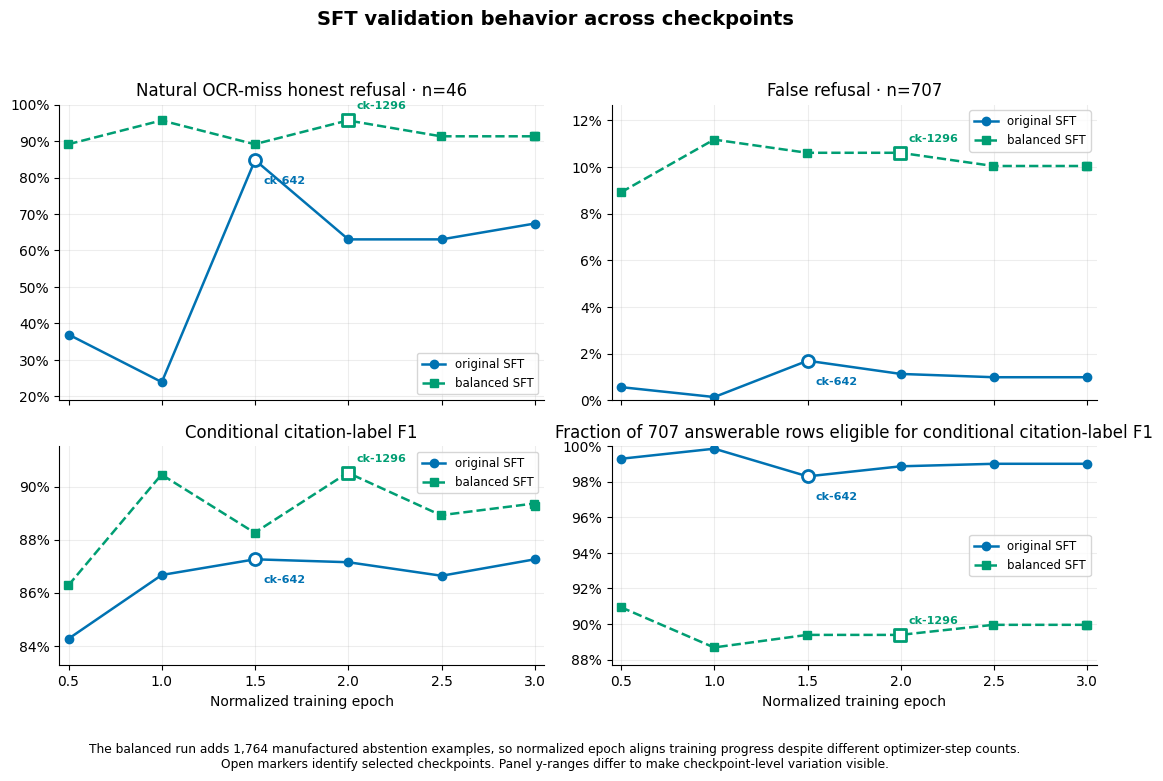

In [ ]:
sft_checkpoint_figure = plot_sft_checkpoint_behavior(ROOT)
display(sft_checkpoint_figure, metadata={"image/png": {"alt": 'Four-panel validation checkpoint curves comparing original and balanced SFT across natural OCR-miss honest refusal, false refusal, conditional citation-label F1, and eligible coverage.'}})
plt.close(sft_checkpoint_figure)

The balanced run learned high natural OCR-miss refusal by the first evaluated
half-epoch checkpoint and remained in that range, but it also produced substantially more
false refusal and lower citation-F1 eligible coverage. Conditional citation-label F1
remained broadly similar.

**How ck-1296 was selected from a validation tie.** Balanced-SFT
checkpoints 648 and 1296 both reached 44/46 honest refusals on the primary
validation metric. A documented secondary tie-break selected ck-1296 because
it had four fewer false refusals—75 rather than 79—and one fewer malformed
output—zero rather than one—for five fewer non-valid outputs overall.
Evaluation loss slightly favored ck-648, 0.092343 versus 0.095555. This
was a practical choice from a near-tie, not evidence that ck-1296 was
decisively superior.

See [`run3_checkpoint_selection.md`](../docs/analysis/run3_checkpoint_selection.md).

---

<a id="s10"></a>

## 10 · Balanced SFT on the test sets

Run-3 is the balanced-SFT model. This section evaluates its selected
checkpoint on the same test populations used for the original SFT seed and
the two earlier GRPO runs, run-1 and run-2. The key question is whether adding
manufactured abstention examples directly to supervised training can produce
strong correct refusal with fewer incorrect refusals than run-2.

In [19]:
# Three evaluation axes, recomputed from committed selected-checkpoint predictions.
from IPython.display import Markdown

systems = [
    ("seed ck-642†",
     "data/checkpoints/eval/sft_B_seed42/gen_manufactured_checkpoint-642.json",
     "data/checkpoints/eval/sft_B_seed42/gen_test_checkpoint-642.json"),
    ("run-1 ck-150",
     "data/checkpoints/eval/grpo_run1_seed42/gen_manufactured_checkpoint-150.json",
     "data/checkpoints/eval/grpo_run1_seed42/gen_test_checkpoint-150.json"),
    ("run-2 ck-150",
     "data/checkpoints/eval/grpo_run2_seed42/gen_manufactured_checkpoint-150.json",
     "data/checkpoints/eval/grpo_run2_seed42/gen_test_checkpoint-150.json"),
    ("balanced SFT ck-1296",
     "data/checkpoints/eval/sft_v3_balanced_nodecoy/gen_manufactured_checkpoint-1296.json",
     "data/checkpoints/eval/sft_v3_balanced_nodecoy/gen_test_checkpoint-1296.json"),
]

lines = [
    "### Three evaluation axes",
    "",
    "| system | clean manufactured honest refusal | natural OCR-miss honest refusal | false refusal on answerable rows |",
    "|---|---:|---:|---:|",
]
for label, manufactured_path, natural_path in systems:
    manufactured_count, manufactured_n = honest_rate(manufactured_path, kept)
    aggregate, counts = score_gen_with_counts(natural_path, test_recs)
    honest_count = counts["honest_abstain"]
    false_count = counts["false_abstain"]
    lines.append(
        f"| {label} | {manufactured_count}/{manufactured_n} "
        f"({manufactured_count/manufactured_n:.3f}) | "
        f"{honest_count}/{aggregate['n_abstain']} "
        f"({honest_count/aggregate['n_abstain']:.3f}) | "
        f"{false_count}/{aggregate['n_answerable']} "
        f"({false_count/aggregate['n_answerable']:.3f}) |"
    )
lines.extend([
    "",
    "† Observed selected-checkpoint test point; see the §5 checkpoint-selection caveat.",
])
display(Markdown("\n".join(lines)))

### Three evaluation axes

| system | clean manufactured honest refusal | natural OCR-miss honest refusal | false refusal on answerable rows |
|---|---:|---:|---:|
| seed ck-642† | 68/235 (0.289) | 62/77 (0.805) | 26/679 (0.038) |
| run-1 ck-150 | 62/235 (0.264) | 59/77 (0.766) | 23/679 (0.034) |
| run-2 ck-150 | 204/235 (0.868) | 77/77 (1.000) | 120/679 (0.177) |
| balanced SFT ck-1296 | 212/235 (0.902) | 71/77 (0.922) | 78/679 (0.115) |

† Observed selected-checkpoint test point; see the §5 checkpoint-selection caveat.

In [20]:
# Paired clean-235 comparisons and the natural-test watch columns.
def honest_map(path, records):
    raw = {r["record_id"]: r.get("raw") for r in json.load(open(path))["records"]}
    missing = [r["record_id"] for r in records if r["record_id"] not in raw]
    assert not missing, f"join coverage: {len(missing)} records absent from {path}"
    return {r["record_id"]: classify(r, raw[r["record_id"]])["bucket"] == "honest_abstain"
            for r in records}

clean_recs = [x for x in manuf if x["exclusion_reason"] is None]
assert len(clean_recs) == 235
H = {lab: honest_map(p, clean_recs) for lab, p in [
    ("seed ck-642",   "data/checkpoints/eval/sft_B_seed42/gen_manufactured_checkpoint-642.json"),
    ("run-2 ck-150",  "data/checkpoints/eval/grpo_run2_seed42/gen_manufactured_checkpoint-150.json"),
    ("run-3 ck-1296", "data/checkpoints/eval/sft_v3_balanced_nodecoy/gen_manufactured_checkpoint-1296.json")]}
for lab, m in H.items():
    print(f"{lab:<14} honest refusal on clean-235: {sum(m.values()):>3}/235 = {sum(m.values())/235:.3f}")

rows3 = [{k: H[k][x["record_id"]] for k in H} for x in clean_recs]
print()
for a, b in (("seed ck-642", "run-3 ck-1296"), ("run-2 ck-150", "run-3 ck-1296")):
    improvements, regressions, paired_p = mcnemar(rows3, a, b)
    print(
        f"{a} -> {b}, clean manufactured honest refusal (n=235): "
        f"improvements={improvements}, regressions={regressions}, "
        f"exact two-sided p={paired_p:.3g}"
    )

t3, t3_counts = score_gen_with_counts(
    "data/checkpoints/eval/sft_v3_balanced_nodecoy/gen_test_checkpoint-1296.json",
    test_recs,
)
ab3 = t3["bucket_rates"]["abstain"]
an3 = t3["bucket_rates"]["answerable"]
f1_3 = t3["citation_f1_gated"]
honest_count = t3_counts["honest_abstain"]
false_count = t3_counts["false_abstain"]
valid_count = t3_counts["valid_citation"]
malformed_count = t3_counts["malformed"]
print(f"\nnatural test split (n={t3['n']}: {t3['n_abstain']} abstain / {t3['n_answerable']} answerable)")
print(
    f"  balanced SFT ck-1296: natural honest refusal "
    f"{honest_count}/{t3['n_abstain']} ({ab3['honest_abstain']:.3f}) | "
    f"false refusal {false_count}/{t3['n_answerable']} "
    f"({an3['false_abstain']:.3f}) | "
    f"structurally valid citation claims {valid_count}/{t3['n_answerable']}"
)
print(
    f"  conditional citation-label F1 {f1_3['micro_f1']:.3f} "
    f"({valid_count}/{t3['n_answerable']} eligible) | "
    f"malformed {malformed_count}/{t3['n']} ({t3['malformed_rate']:.4f})"
)
print("  false-refusal references: seed 26/679 | run-1 23/679 | run-2 120/679")

seed ck-642    honest refusal on clean-235:  68/235 = 0.289
run-2 ck-150   honest refusal on clean-235: 204/235 = 0.868
run-3 ck-1296  honest refusal on clean-235: 212/235 = 0.902

seed ck-642 -> run-3 ck-1296, clean manufactured honest refusal (n=235): improvements=144, regressions=0, exact two-sided p=8.97e-44
run-2 ck-150 -> run-3 ck-1296, clean manufactured honest refusal (n=235): improvements=14, regressions=6, exact two-sided p=0.115

natural test split (n=756: 77 abstain / 679 answerable)
  balanced SFT ck-1296: natural honest refusal 71/77 (0.922) | false refusal 78/679 (0.115) | structurally valid citation claims 601/679
  conditional citation-label F1 0.876 (601/679 eligible) | malformed 0/756 (0.0000)
  false-refusal references: seed 26/679 | run-1 23/679 | run-2 120/679


**Run-2 and balanced SFT make different trade-offs.** On the clean manufactured
set, run-2 refuses correctly on **204/235** rows and balanced SFT on **212/235**.
Among the rows where they differ, balanced SFT fixes **14** run-2 failures and
breaks **6** rows that run-2 handled correctly.

Their behavior separates more clearly on the other two populations:

| System | Clean manufactured correct refusal | Natural OCR-miss correct refusal | Incorrect refusal on answerable rows |
|---|---:|---:|---:|
| Run-2 shaped GRPO | 204/235 | 77/77 | 120/679 |
| Balanced SFT | 212/235 | 71/77 | 78/679 |

Run-2 refuses correctly on every natural OCR-miss row, but it also refuses
incorrectly much more often. Balanced SFT gives up six correct natural OCR-miss
refusals while reducing incorrect refusal by 42 rows. These systems therefore
make different trade-offs rather than yielding one universal winner.

Balanced SFT also improves substantially over the original SFT seed on the
clean manufactured set. The complete paired counts and exact p-values are in
the optional statistical detail below.

---

<a id="s11"></a>

## 11 · Run 4 — pricing over-refusal

Run-4a and run-4b both continue balanced SFT checkpoint 1296 with GRPO. Run-4a retains
the shaped-GRPO reward settings; run-4b changes one base value by adding a −0.2 penalty
for false refusal. The comparison asks whether that penalty reduces over-refusal and what
refusal ability is lost in exchange.

### Training dynamics and held-out validation

Run-4 was the fully instrumented follow-up: both variants started from the balanced-SFT
checkpoint, saw the same ordered training examples, logged reward and sampled outcomes
for all 150 optimizer steps, and were evaluated every ten steps on the same 112 validation
examples. Run-4b differs by the −0.2 false-refusal penalty.

#### Mean GRPO reward

Each optimizer step contains four training examples and eight sampled completions per
example. Raw reward is noisy, so the exponential moving average shows the broader trend.
The variants use slightly different numeric reward functions, so absolute reward levels
should be interpreted within each run. Checkpoints were selected using the same 112
validation examples evaluated every ten steps—not by choosing the maximum training
reward.

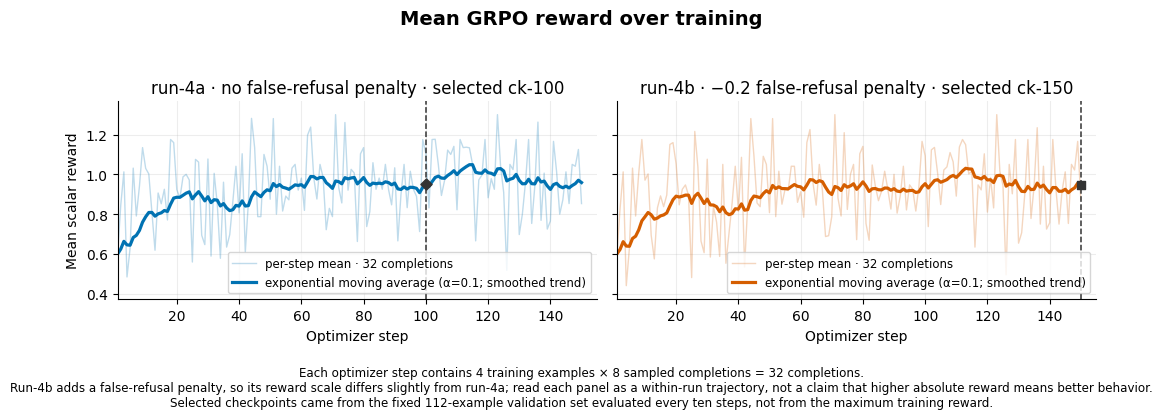

In [ ]:
run4_reward_figure = plot_run4_reward_dynamics(ROOT)
display(run4_reward_figure, metadata={"image/png": {"alt": 'Two-panel line chart of per-step mean GRPO reward and exponential moving averages for run-4a and run-4b, with selected checkpoints marked.'}})
plt.close(run4_reward_figure)

Both runs improved rapidly during early training and then entered a noisy
plateau. Reward alone does not reveal whether the model improved through honest refusal
or through a less desirable behavioral shift, motivating the outcome-composition view
below.

#### Sampled outcome composition

The top panels include completions for abstention-target training examples; the bottom
panels include completions for answerable training examples. Fractions use denominators
within each target type. A blank step means none of the four examples at that optimizer
step belonged to that target type; it is not a zero rate.

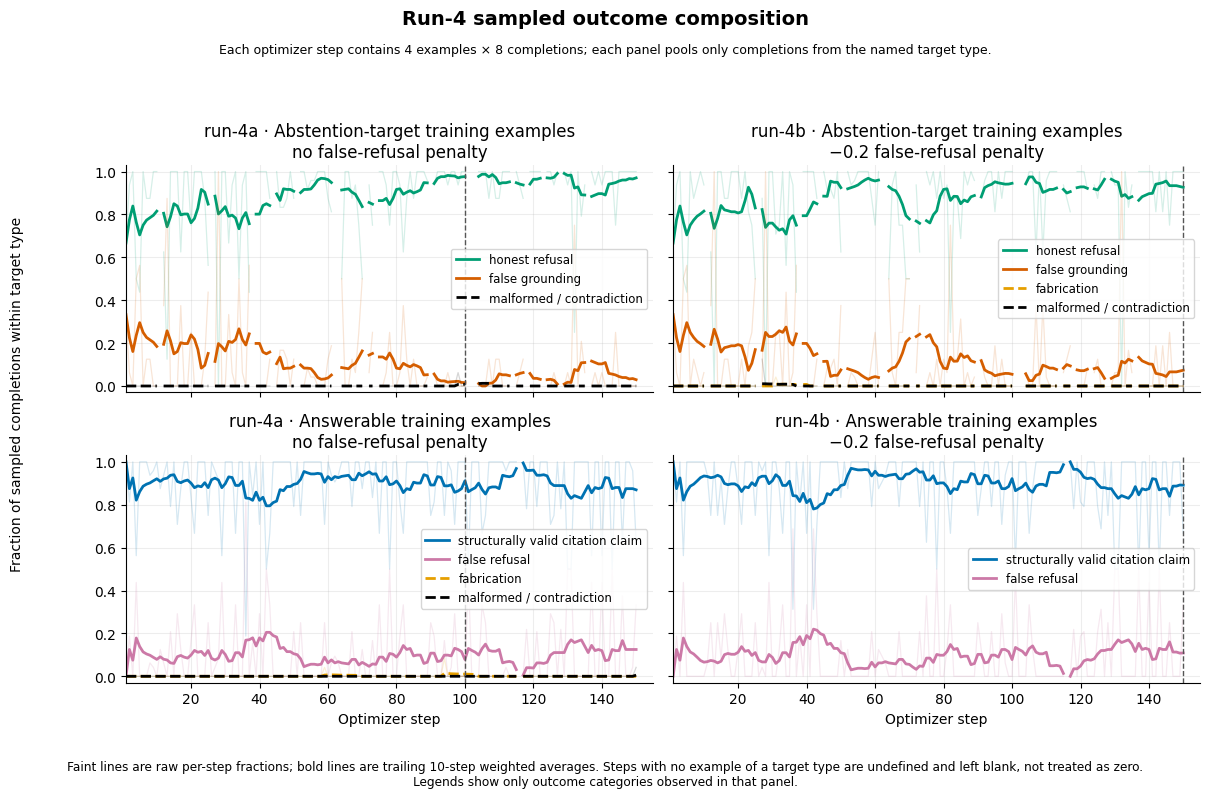

In [ ]:
run4_outcome_figure = plot_run4_outcome_dynamics(ROOT)
display(run4_outcome_figure, metadata={"image/png": {"alt": 'Four-panel line chart of sampled outcome fractions over run-4a and run-4b training, split between abstention-target and answerable examples.'}})
plt.close(run4_outcome_figure)

On abstention-target examples, honest refusal generally rose while false
grounding fell. On answerable examples, structurally valid citation claims remained the
majority while false refusal fluctuated. Because these training curves average over
changing minibatches and sampled completions, the run-4b effect is difficult to judge
visually. The paired frozen-test comparison—evaluating both selected systems on exactly
the same rows—is the clearer measure of the final change.

#### Checkpoint selection

The same 64 abstention-target and 48 answerable validation examples were evaluated at
every ten-step checkpoint. They were held out from weight updates but repeatedly used for
checkpoint selection; they are not an untouched test set. Run-4a checkpoint 100 was
selected from a six-way tie by the documented earliest-step rule. Run-4b checkpoint 150
uniquely reached the best honest-refusal count.

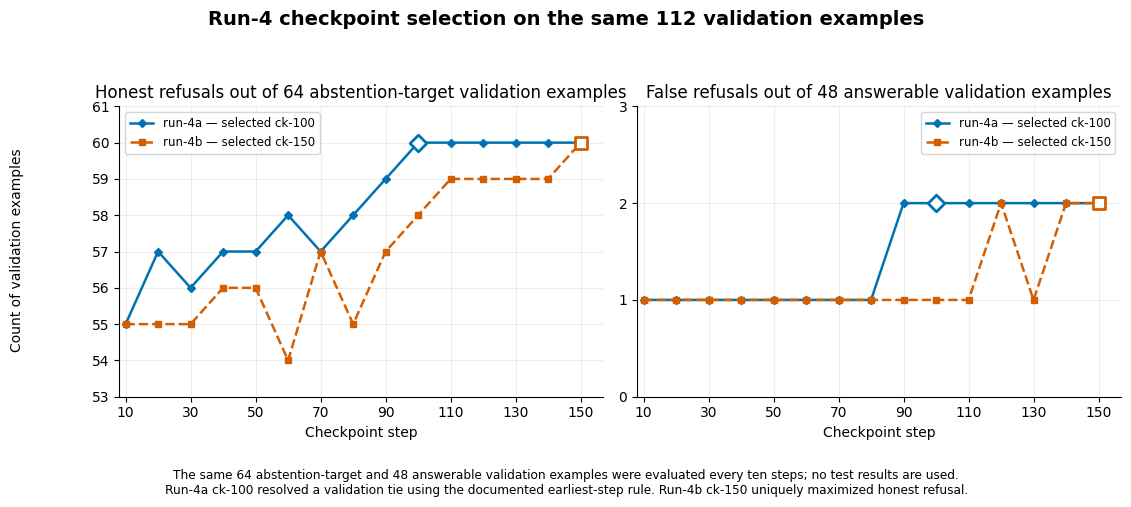

In [ ]:
run4_validation_figure = plot_run4_validation_dynamics(ROOT)
display(run4_validation_figure, metadata={"image/png": {"alt": 'Two-panel checkpoint curve of honest-refusal and false-refusal counts for run-4a and run-4b on the shared validation set.'}})
plt.close(run4_validation_figure)

Both selected checkpoints reached 60/64 honest refusals and 2/48 false
refusals on this validation set. Conditional citation-label F1 remained between
approximately 0.93 and 0.94 with 46–47 of 48 answerable rows eligible, so the main
checkpoint-level movement was in refusal behavior.

### Frozen-test comparisons

#### Balanced SFT versus run-4a

On the clean manufactured set, correct refusal increases from **212/235** for
balanced SFT to **217/235** for run-4a. Run-4a fixes **5** balanced-SFT failures
and breaks **0** rows that balanced SFT handled correctly.

This is a small but consistently favorable change on the five rows where the
systems differ. The exact paired result is retained in the optional statistical
detail below.

#### Run-4a versus run-4b

Before run-4b launched, the local run-4 analysis plan designated incorrect
refusal on the answerable rows as the primary comparison against run-4a.

Incorrect refusal falls from **99/679 to 91/679**. Run-4b recovers **10** rows
that run-4a refused incorrectly, while newly refusing **2** rows that run-4a
answered.

On the clean manufactured set, both systems refuse correctly on **217/235**
rows. Their totals are equal, although one row improves and one regresses.

On the natural OCR-miss set, correct refusal falls from **76/77 to 74/77**. The
two lost rows become false grounding.

Run-4b therefore improves one part of the trade-off—incorrect refusal—without
improving every metric. Exact paired results are retained in the optional
statistical detail below. These are final named-checkpoint test comparisons,
not checkpoint-selection curves. See
[`run4a_test_results.md`](../docs/analysis/run4a_test_results.md) and
[`run4b_test_results.md`](../docs/analysis/run4b_test_results.md).

### Final refusal trade-offs

The figure compares incorrect refusal on answerable rows with correct refusal
after manufactured evidence removal. Each point also shows correct refusal on
the separate natural OCR-miss set.

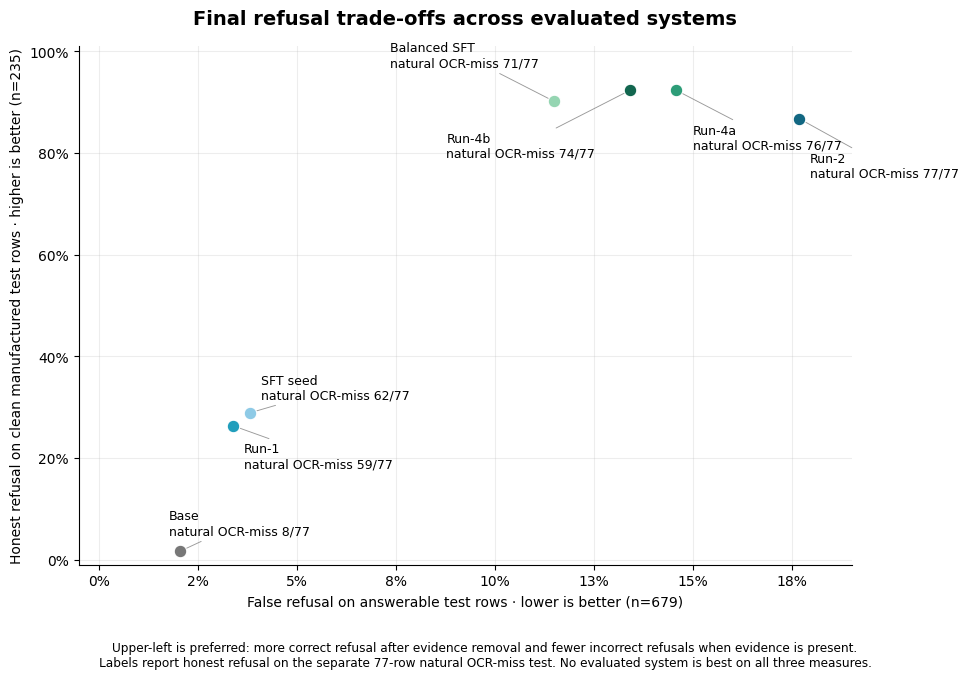

In [ ]:
final_operating_figure = plot_final_operating_points(ROOT)
display(final_operating_figure, metadata={"image/png": {"alt": 'Scatter plot of final evaluated systems showing false refusal on answerable test rows versus honest refusal on clean manufactured rows, annotated with natural OCR-miss results.'}})
plt.close(final_operating_figure)

No evaluated system is best on all three measures.

Run-2 reaches **77/77** correct refusals on natural OCR misses but also has the
most incorrect refusals, **120/679**. Balanced SFT reduces incorrect refusal to
**78/679** and improves clean manufactured refusal from **204/235 to 212/235**,
while natural OCR-miss refusal falls from **77/77 to 71/77**.

Starting from balanced SFT, run-4b has **91/679** incorrect refusals, compared
with **99/679** for run-4a. Both reach **217/235** on clean manufactured rows,
while run-4b records **74/77** rather than **76/77** on natural OCR misses.

Balanced SFT still has fewer incorrect refusals than run-4b—**78/679 versus
91/679**—while run-4b refuses correctly on more clean manufactured and natural
OCR-miss rows: **217/235 and 74/77**, compared with **212/235 and 71/77**.

### Retrospective matched-pool SFT follow-up

This retrospective follow-up continued the original SFT ck-642 adapter with
supervised training on the original 5,000-record run-1/run-2 pool: 3,000
answerable and 2,000 manufactured records, including 377 recurrence/decoy cases.
Training used 150 optimizer steps and 600 supervised-example exposures, with
step 150 fixed in advance for evaluation.

Both continuations started from SFT ck-642 and used the same 5,000-record
training pool, with 600 prompt exposures each. This provided a closer
comparison of further supervised training and GRPO.

Continued SFT on the original GRPO pool raised correct manufactured refusal from
**68/235 to 195/235**, while increasing incorrect refusal on answerable questions
from **26/679 to 83/679**. Compared with shaped GRPO run-2, it produced nine fewer
correct manufactured refusals and one fewer correct natural OCR-miss refusal,
but 37 fewer incorrect refusals. In this run, further supervised training with
manufactured examples recovered much of run-2’s refusal improvement. The
original SFT checkpoint therefore did not establish a limit of SFT.

The follow-up is included in the comparison table below; the existing figure
retains its original seven-system view.

In [25]:
# Recompute the original final values and load the matched-pool follow-up from the compact public manifest.
import math
from html import escape

from IPython.display import HTML, Markdown
from scripts.public_metrics import load_public_manifest

final_prediction_paths = {
    "seed": {
        "label": "SFT seed ck-642",
        "manufactured": "data/checkpoints/eval/sft_B_seed42/gen_manufactured_checkpoint-642.json",
        "test": "data/checkpoints/eval/sft_B_seed42/gen_test_checkpoint-642.json",
    },
    "run1": {
        "label": "run-1 ck-150",
        "manufactured": "data/checkpoints/eval/grpo_run1_seed42/gen_manufactured_checkpoint-150.json",
        "test": "data/checkpoints/eval/grpo_run1_seed42/gen_test_checkpoint-150.json",
    },
    "run2": {
        "label": "run-2 ck-150",
        "manufactured": "data/checkpoints/eval/grpo_run2_seed42/gen_manufactured_checkpoint-150.json",
        "test": "data/checkpoints/eval/grpo_run2_seed42/gen_test_checkpoint-150.json",
    },
    "balanced": {
        "label": "Balanced SFT ck-1296",
        "manufactured": "data/checkpoints/eval/sft_v3_balanced_nodecoy/gen_manufactured_checkpoint-1296.json",
        "test": "data/checkpoints/eval/sft_v3_balanced_nodecoy/gen_test_checkpoint-1296.json",
    },
    "run4a": {
        "label": "run-4a ck-100",
        "manufactured": "data/checkpoints/eval/grpo_run4a_seed42/gen_manufactured_checkpoint-100.json",
        "test": "data/checkpoints/eval/grpo_run4a_seed42/gen_test_checkpoint-100.json",
    },
    "run4b": {
        "label": "run-4b ck-150",
        "manufactured": "data/checkpoints/eval/grpo_run4b_seed42/gen_manufactured_checkpoint-150.json",
        "test": "data/checkpoints/eval/grpo_run4b_seed42/gen_test_checkpoint-150.json",
    },
}

final_clean_recs = [record for record in manuf if record["exclusion_reason"] is None]
final_natural_recs = [record for record in test_recs if not record["gold_localized"]]
final_answerable_recs = [record for record in test_recs if record["gold_localized"]]
assert len(final_clean_recs) == 235
assert len(final_natural_recs) == 77
assert len(final_answerable_recs) == 679


def _non_false_refusal_map(path: str, records: list[dict]) -> dict[str, bool]:
    raw = {row["record_id"]: row.get("raw") for row in json.load(open(path))["records"]}
    missing = [record["record_id"] for record in records if record["record_id"] not in raw]
    assert not missing, f"join coverage: {len(missing)} records absent from {path}"
    return {
        record["record_id"]: classify(record, raw[record["record_id"]])["bucket"] != "false_abstain"
        for record in records
    }


final_clean_honest = {
    key: honest_map(paths["manufactured"], final_clean_recs)
    for key, paths in final_prediction_paths.items()
}
final_natural_honest = {
    key: honest_map(paths["test"], final_natural_recs)
    for key, paths in final_prediction_paths.items()
}
final_answerable_not_false_refusal = {
    key: _non_false_refusal_map(paths["test"], final_answerable_recs)
    for key, paths in final_prediction_paths.items()
}

final_metrics = {}
for key, paths in final_prediction_paths.items():
    aggregate, counts = score_gen_with_counts(paths["test"], test_recs)
    citation = aggregate["citation_f1_gated"]
    final_metrics[key] = {
        "clean_correct": sum(final_clean_honest[key].values()),
        "natural_correct": counts["honest_abstain"],
        "incorrect_refusal": counts["false_abstain"],
        "citation_f1": citation["micro_f1"],
        "eligible": counts["valid_citation"],
    }
    assert final_metrics[key]["natural_correct"] == sum(final_natural_honest[key].values())

matched_public = load_public_manifest(ROOT / "artifacts/public")["matched_pool_sft_followup"]
assert matched_public["checkpoint"] == 150
assert matched_public["training_design"]["supervised_example_exposures"] == 600
matched_headline = matched_public["headline_metrics"]
final_metrics["matched"] = {
    "clean_correct": matched_headline["clean_manufactured_correct_refusal"]["count"],
    "natural_correct": matched_headline["natural_ocr_miss_correct_refusal"]["count"],
    "incorrect_refusal": matched_headline["incorrect_refusal_on_answerable"]["count"],
    "citation_f1": matched_headline["conditional_citation_label_f1"]["micro_f1"],
    "eligible": matched_headline["conditional_citation_label_f1"]["eligible_count"],
}
final_display_labels = {
    key: paths["label"] for key, paths in final_prediction_paths.items()
}
final_display_labels["matched"] = matched_public["display_name"]

expected_final_metrics = {
    "seed": (68, 62, 26, 0.8412, 650),
    "run1": (62, 59, 23, 0.8296, 655),
    "run2": (204, 77, 120, 0.8694, 557),
    "matched": (195, 76, 83, 0.8592, 596),
    "balanced": (212, 71, 78, 0.8758, 601),
    "run4a": (217, 76, 99, 0.8895, 580),
    "run4b": (217, 74, 91, 0.8775, 588),
}
for key, expected in expected_final_metrics.items():
    clean_correct, natural_correct, incorrect_refusal, citation_f1, eligible = expected
    observed = final_metrics[key]
    assert observed["clean_correct"] == clean_correct
    assert observed["natural_correct"] == natural_correct
    assert observed["incorrect_refusal"] == incorrect_refusal
    assert round(observed["citation_f1"], 4) == citation_f1
    assert observed["eligible"] == eligible

metric_table = [
    "### Recomputed final comparison values",
    "",
    "| System | Clean manufactured correct refusal | Natural OCR-miss correct refusal | Incorrect refusal on answerable rows | Conditional citation-label F1 |",
    "|---|---:|---:|---:|---:|",
]
for key in ("matched", "balanced", "run4a", "run4b"):
    row = final_metrics[key]
    metric_table.append(
        f"| {final_display_labels[key]} | "
        f"{row['clean_correct']}/235 | "
        f"{row['natural_correct']}/77 | "
        f"{row['incorrect_refusal']}/679 | "
        f"{row['citation_f1']:.4f} ({row['eligible']}/679 eligible) |"
    )
display(Markdown("\n".join(metric_table)))


def _paired_result(first: str, second: str, maps: dict[str, dict[str, bool]], records: list[dict]) -> tuple[int, int, float]:
    rows = [
        {"first": maps[first][record["record_id"]], "second": maps[second][record["record_id"]]}
        for record in records
    ]
    return mcnemar(rows, "first", "second")


def _format_p_value(p_value: float) -> str:
    if p_value == 1.0:
        return "1.0"
    if p_value < 0.001:
        return f"{p_value:.2e}"
    if p_value < 0.1:
        return f"{p_value:.4f}"
    return f"{p_value:.3g}"


def _counted_rows(count: int, plural_label: str) -> str:
    label = plural_label[:-1] if count == 1 and plural_label.endswith("rows") else plural_label
    return f"{count} {escape(label)}"


paired_specs = [
    {
        "comparison": "SFT seed ck-642 -> run-1 ck-150",
        "outcome": "Clean manufactured correct refusal",
        "first": "seed",
        "second": "run1",
        "maps": final_clean_honest,
        "records": final_clean_recs,
        "second_label": "improved rows",
        "first_label": "regressed rows",
        "expected": (1, 7, 0.0703125),
    },
    {
        "comparison": "SFT seed ck-642 -> run-2 ck-150",
        "outcome": "Clean manufactured correct refusal",
        "first": "seed",
        "second": "run2",
        "maps": final_clean_honest,
        "records": final_clean_recs,
        "second_label": "improved rows",
        "first_label": "regressed rows",
        "expected": (136, 0, 2.2958874039497803e-41),
    },
    {
        "comparison": "run-2 ck-150 -> Balanced SFT ck-1296",
        "outcome": "Clean manufactured correct refusal",
        "first": "run2",
        "second": "balanced",
        "maps": final_clean_honest,
        "records": final_clean_recs,
        "second_label": "improved rows",
        "first_label": "regressed rows",
        "expected": (14, 6, 0.11531829833984375),
    },
    {
        "comparison": "SFT seed ck-642 -> Balanced SFT ck-1296",
        "outcome": "Clean manufactured correct refusal",
        "first": "seed",
        "second": "balanced",
        "maps": final_clean_honest,
        "records": final_clean_recs,
        "second_label": "improved rows",
        "first_label": "regressed rows",
        "expected": (144, 0, 8.96831017167883e-44),
    },
    {
        "comparison": "Balanced SFT ck-1296 -> run-4a ck-100",
        "outcome": "Clean manufactured correct refusal",
        "first": "balanced",
        "second": "run4a",
        "maps": final_clean_honest,
        "records": final_clean_recs,
        "second_label": "improved rows",
        "first_label": "regressed rows",
        "expected": (5, 0, 0.0625),
    },
    {
        "comparison": "run-4a ck-100 -> run-4b ck-150",
        "outcome": "Incorrect refusal on answerable rows",
        "first": "run4a",
        "second": "run4b",
        "maps": final_answerable_not_false_refusal,
        "records": final_answerable_recs,
        "second_label": "recovered rows",
        "first_label": "newly refused rows",
        "expected": (10, 2, 0.03857421875),
    },
    {
        "comparison": "run-4a ck-100 -> run-4b ck-150",
        "outcome": "Clean manufactured correct refusal",
        "first": "run4a",
        "second": "run4b",
        "maps": final_clean_honest,
        "records": final_clean_recs,
        "second_label": "improved rows",
        "first_label": "regressed rows",
        "expected": (1, 1, 1.0),
    },
    {
        "comparison": "run-4a ck-100 -> run-4b ck-150",
        "outcome": "Natural OCR-miss correct refusal",
        "first": "run4a",
        "second": "run4b",
        "maps": final_natural_honest,
        "records": final_natural_recs,
        "second_label": "improved rows",
        "first_label": "regressed rows",
        "expected": (0, 2, 0.5),
    },
]

paired_table_rows = []
for spec in paired_specs:
    favor_second, favor_first, p_value = _paired_result(
        spec["first"], spec["second"], spec["maps"], spec["records"]
    )
    expected_second, expected_first, expected_p = spec["expected"]
    assert favor_second == expected_second
    assert favor_first == expected_first
    assert math.isclose(p_value, expected_p, rel_tol=0.0, abs_tol=1e-15)
    paired_table_rows.append(
        "<tr>"
        f"<td>{escape(spec['comparison'])}</td>"
        f"<td>{escape(spec['outcome'])}</td>"
        f"<td>{_counted_rows(favor_second, spec['second_label'])}</td>"
        f"<td>{_counted_rows(favor_first, spec['first_label'])}</td>"
        f"<td>{_format_p_value(p_value)}</td>"
        "</tr>"
    )

paired_table = """
<details>
<summary>Optional paired-comparison statistics</summary>
<table>
<thead>
<tr>
<th>comparison, first -> second system</th>
<th>evaluation outcome</th>
<th>rows favoring the second system</th>
<th>rows favoring the first system</th>
<th>exact two-sided p-value</th>
</tr>
</thead>
<tbody>
{rows}
</tbody>
</table>
</details>
""".format(rows="\n".join(paired_table_rows))
display(HTML(paired_table))


### Recomputed final comparison values

| System | Clean manufactured correct refusal | Natural OCR-miss correct refusal | Incorrect refusal on answerable rows | Conditional citation-label F1 |
|---|---:|---:|---:|---:|
| Matched-pool SFT continuation ck-150 | 195/235 | 76/77 | 83/679 | 0.8592 (596/679 eligible) |
| Balanced SFT ck-1296 | 212/235 | 71/77 | 78/679 | 0.8758 (601/679 eligible) |
| run-4a ck-100 | 217/235 | 76/77 | 99/679 | 0.8895 (580/679 eligible) |
| run-4b ck-150 | 217/235 | 74/77 | 91/679 | 0.8775 (588/679 eligible) |

"comparison, first -> second system",evaluation outcome,rows favoring the second system,rows favoring the first system,exact two-sided p-value
SFT seed ck-642 -> run-1 ck-150,Clean manufactured correct refusal,1 improved row,7 regressed rows,0.0703
SFT seed ck-642 -> run-2 ck-150,Clean manufactured correct refusal,136 improved rows,0 regressed rows,2.30e-41
run-2 ck-150 -> Balanced SFT ck-1296,Clean manufactured correct refusal,14 improved rows,6 regressed rows,0.115
SFT seed ck-642 -> Balanced SFT ck-1296,Clean manufactured correct refusal,144 improved rows,0 regressed rows,8.97e-44
Balanced SFT ck-1296 -> run-4a ck-100,Clean manufactured correct refusal,5 improved rows,0 regressed rows,0.0625
run-4a ck-100 -> run-4b ck-150,Incorrect refusal on answerable rows,10 recovered rows,2 newly refused rows,0.0386
run-4a ck-100 -> run-4b ck-150,Clean manufactured correct refusal,1 improved row,1 regressed row,1.0
run-4a ck-100 -> run-4b ck-150,Natural OCR-miss correct refusal,0 improved rows,2 regressed rows,0.5


<a id="s12"></a>

## 12 · Limitations

- **Citation checks have limits.** The scorer verifies the output format,
  checks that the fields agree, and confirms that cited OCR IDs exist. Those
  checks cannot prove that the cited text actually answers the question.
  Citation-label F1 compares against automatically created labels from the
  fuzzy localizer rather than human-verified evidence spans, and it is
  calculated only on outputs that make a valid citation claim. This is why
  the notebook reports eligible coverage, incorrect refusal, and worked
  examples alongside F1.

- **Some questions come from the same document.** The clean manufactured set
  contains 235 questions from 75 documents. To check whether documents with
  several questions were driving the strongest result, the SFT-seed-to-run-2
  comparison was also summarized by document: **60 documents improved, none
  regressed, and 15 tied**.

- **A small amount of image overlap was found across splits.** One exact page
  duplicate appears across train and test, and one near-duplicate appears
  across train and validation. The exact duplicate contributes four
  answerable test rows and no clean manufactured rows. Removing those four
  rows changes run-2’s incorrect-refusal result only slightly, from
  **120/679 to 119/675**. These test sets were examined more than once during
  development, rather than being reserved for one final evaluation. The
  results support comparisons among this project’s systems, but should not
  be presented as performance on a completely untouched external benchmark.

- **Training variation was not measured.** Each training setting was run
  once. The results describe these runs but do not show how much they would
  vary across different random seeds.

- **Recalculating scores and recreating training are different tasks.** Saved
  model outputs let readers recalculate the reported scores for every system
  except matched-pool SFT, using `scripts/eval_scorer.py` as shown earlier in
  the notebook. For that run, the repository currently includes only
  [saved summary results](../artifacts/public/manifest.json); the individual
  model outputs remain local. The repository does not include every trained
  adapter, complete set of historical settings, exact training environment,
  or source page image.

In [25]:
# Compact sensitivity checks supporting the closing limitations.
# The cluster bootstrap resamples source documents with replacement and recomputes
# the row-weighted honest-refusal rate difference in each resample.
from collections import defaultdict
from math import comb

import numpy as np

comparison_rows = [
    json.loads(line)
    for line in open("docs/analysis/mcnemar_seed_vs_grpo_per_record.jsonl")
]
current_exclusions = {
    row["record_id"] for row in manuf if row["exclusion_reason"] is not None
}
clean_comparison = [
    row for row in comparison_rows
    if row["record_id"] not in current_exclusions
]
assert len(clean_comparison) == 235

changes_by_doc = defaultdict(list)
for row in clean_comparison:
    changes_by_doc[row["doc_id"]].append(
        int(row["honest_run2_ck150"]) - int(row["honest_seed"])
    )

document_ids = sorted(changes_by_doc)
assert len(document_ids) == 75
document_delta = np.array([
    sum(changes_by_doc[doc_id]) for doc_id in document_ids
])
document_size = np.array([
    len(changes_by_doc[doc_id]) for doc_id in document_ids
])

rng = np.random.default_rng(42)
bootstrap_deltas = []
for _ in range(20):
    sampled_documents = rng.integers(
        0,
        len(document_ids),
        size=(10_000, len(document_ids)),
    )
    bootstrap_deltas.append(
        document_delta[sampled_documents].sum(axis=1)
        / document_size[sampled_documents].sum(axis=1)
    )
bootstrap_deltas = np.concatenate(bootstrap_deltas)
lower, upper = np.quantile(bootstrap_deltas, [0.025, 0.975])

improved_documents = int((document_delta > 0).sum())
declined_documents = int((document_delta < 0).sum())
tied_documents = int((document_delta == 0).sum())

def exact_two_sided_sign_test(improved: int, declined: int) -> float:
    non_ties = improved + declined
    if non_ties == 0:
        return 1.0
    smaller_side = min(improved, declined)
    lower_tail = sum(
        comb(non_ties, successes)
        for successes in range(smaller_side + 1)
    ) * (0.5 ** non_ties)
    return min(1.0, 2.0 * lower_tail)

sign_test_p = exact_two_sided_sign_test(
    improved_documents,
    declined_documents,
)

print(
    "seed ck-642 -> run-2 ck-150, clean-235 document sensitivity: "
    f"235 rows / {len(document_ids)} documents; "
    f"row-weighted cluster-bootstrap 95% interval "
    f"[{lower:.3f}, {upper:.3f}]; "
    f"document directions {improved_documents} improve / "
    f"{declined_documents} decline / {tied_documents} tie; "
    f"two-sided exact sign-test p={sign_test_p:.2e}"
)

# doc_id=4386 is the previously identified exact duplicate test page.
# This calculation measures the effect of excluding its four answerable rows;
# it does not rediscover or revalidate the image-level duplicate.
duplicate_doc_id = 4386
duplicate_rows = [
    row for row in test_recs if row["doc_id"] == duplicate_doc_id
]
assert len(duplicate_rows) == 4
assert all(row["gold_localized"] for row in duplicate_rows)

duplicate_excluded_test = [
    row for row in test_recs if row["doc_id"] != duplicate_doc_id
]
run2_path = (
    "data/checkpoints/eval/grpo_run2_seed42/"
    "gen_test_checkpoint-150.json"
)
run2_full, run2_full_counts = score_gen_with_counts(run2_path, test_recs)
run2_filtered, run2_filtered_counts = score_gen_with_counts(
    run2_path,
    duplicate_excluded_test,
)

print(
    "run-2 duplicate-excluded false-refusal sensitivity: "
    f"{run2_full_counts['false_abstain']}/{run2_full['n_answerable']} -> "
    f"{run2_filtered_counts['false_abstain']}/"
    f"{run2_filtered['n_answerable']}"
)

seed ck-642 -> run-2 ck-150, clean-235 document sensitivity: 235 rows / 75 documents; row-weighted cluster-bootstrap 95% interval [0.502, 0.653]; document directions 60 improve / 0 decline / 15 tie; two-sided exact sign-test p=1.73e-18
run-2 duplicate-excluded false-refusal sensitivity: 120/679 -> 119/675


## Takeaway

FaithfulDocVQA separates two questions that document-VQA systems often blur:
can the model read an answer from the page, and can it support that answer
using the supplied OCR evidence?

The original SFT seed learned to refuse on natural OCR misses but generalized
poorly when cited evidence was deliberately removed. On the clean manufactured set, Run-2 corrected 136 errors made by the
original SFT seed without introducing new errors on that set, while incorrect
refusal on answerable questions increased to 120/679. The matched-pool
SFT continuation recovered much of that gain with fewer incorrect refusals,
strengthening the supervised comparison. Balanced SFT produced **212/235**
correct refusals with **78/679** incorrect refusals. The later GRPO variants
increased clean manufactured refusal to **217/235**, while incorrect refusal
was **99/679** for run-4a and **91/679** for run-4b.

No system was best on every evaluation population. Across these configurations
and single runs, balanced SFT had stronger clean manufactured refusal and
slightly fewer incorrect refusals than the matched continuation, while the
continuation had stronger natural OCR-miss refusal. The practical lesson is to
measure correct and incorrect refusal together rather than treat one training
method as universally best.